# DLENT-RT — Main algorithm analysis (theory model)

One configuration only: `BASE = apply_overrides(cfg, {"bid.sigma": 0.3})` on top of
`configs/default.yaml`, with the default normalization (`quantile_linear`, q = 0.90, no common divisor,
s_C frozen in Phase 0). Reward in dollars, unbounded.
Theoretical setting: the true duration of an admitted job is known at arrival (`model.kind = "theory"`).

Notebook-only knob: `capacity_scale` multiplies the initial cluster capacity c_i (CPU and RAM) **before Phase 0**.
It is an override inside this notebook, not a change of the default. Sweep: capacity_scale in {0.5, 1.0} (`DLENT_SCALES` to change);
every section below is for the baseline 1.0, the sweep is the compact table + occupancy figure of Section 6.

Sections: 0. Setup &middot; 1. Distributions (C.1) &middot; 2. Per-phase margin (C.2) &middot;
3. Results per phase (C.3) &middot; 4. Accuracy per phase (C.4) &middot; 5. Baselines and regret (C.5) &middot;
6. capacity_scale sweep &middot; 7. Anomalies.

**Config: the COMMITTED `configs/default.yaml`** (`git show HEAD:configs/default.yaml` through a temporary file,
`scripts/regime_config.py`); an uncommitted edit of the working copy is never read. With `DLENT_REGIME=<path>` the
capacity block of that named regime (read from git HEAD too) overrides the committed capacity, and every output goes
to the regime's own folders; the run marker prints the commit and both blobs.
Sections 9–11 (week 30): benchmark ladder with the bucketed job-level MILP, reward split per model, oversize jobs
(10b), and the
same ladder at f = 0.2 with `drop_jobs_exceeding_capacity`.

Rebuild/execute: `python notebooks/src/build.py 03_main_algorithm_analysis --execute`.
Data: real trace only, `data/batch_may2019_30k.csv` + `data/grid_data_may_2019.csv` (no synthetic data).
Fewer scales for a quick run: `DLENT_SCALES=1.0`.

## Section 0: Setup and configuration

In [1]:
# RUN MARKER: which code and which config produced the numbers of this notebook
import os, subprocess
from pathlib import Path
_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "dlent_rt").is_dir())
def _git(*a):
    return subprocess.check_output(["git", "-C", str(_ROOT), *a], text=True).strip()
GIT_COMMIT = _git("rev-parse", "HEAD")
YAML_BLOB = _git("rev-parse", "HEAD:configs/default.yaml")
YAML_WORKING_COPY_EDITED = bool(_git("status", "--porcelain", "--", "configs/default.yaml"))
# named regime (optional): DLENT_REGIME=configs/regime_<name>.yaml overrides ONLY the capacity of the committed default
REGIME = os.environ.get("DLENT_REGIME") or None
REGIME_BLOB = _git("rev-parse", f"HEAD:{REGIME}") if REGIME else None
REGIME_TAG = Path(REGIME).stem.replace("regime_", "") if REGIME else None
print(f"NB03 RUN MARKER  commit={GIT_COMMIT}  configs/default.yaml blob={YAML_BLOB}  "
      f"regime={REGIME or 'none'}  regime blob={REGIME_BLOB or '-'}")
print("config: git show HEAD:configs/default.yaml" + (f" + the capacity block of git show HEAD:{REGIME}" if REGIME else "")
      + " -> temporary file (scripts/regime_config.py), deleted after loading")
print(f"working-copy configs/default.yaml edited: {YAML_WORKING_COPY_EDITED} (not used)")
import time as _time
print(f"run started: {_time.strftime('%Y-%m-%d %H:%M:%S')}")

NB03 RUN MARKER  commit=3549fc97caa8d93b2d86262bc166391a07aad322  configs/default.yaml blob=68e7bd76b57c376cae6d74139f11cc456559520b  regime=configs/regime_small_cluster.yaml  regime blob=a0d29b5313ea41184961aa085366bc988c5dd7d0
config: git show HEAD:configs/default.yaml + the capacity block of git show HEAD:configs/regime_small_cluster.yaml -> temporary file (scripts/regime_config.py), deleted after loading
working-copy configs/default.yaml edited: True (not used)
run started: 2026-10-23 13:37:25


In [2]:
import os, sys, time, warnings, dataclasses
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import lognorm
from IPython.display import display
warnings.simplefilter("ignore")

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "dlent_rt").is_dir())
sys.path.insert(0, str(ROOT))

from dlent_rt.config import load_config
from dlent_rt.data import load_dataset
from dlent_rt.phase0 import run_phase0, assign_type_ids, type_arrays
from dlent_rt.lp_oracle import solve_lp_rs
from dlent_rt.reward import type_reward, weighted_quantile as _weighted_quantile
from dlent_rt.models.theory import TheoryModel
from dlent_rt.benchmarks import Benchmarks, regret
from dlent_rt.models.policy import run_static, run_policy, TypeGreedyPolicy, JobGreedyPolicy
from dlent_rt.models.core.error_params import make_error_params

plt.rcParams["figure.figsize"] = (13, 3.6)
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 60)

# palette (notebook 01 conventions: named matplotlib colours)
C_CV, C_PI, C_C, C_BID = "steelblue", "darkorange", "gray", "steelblue"
C_CPU, C_RAM = "steelblue", "darkorange"
DEC_ORDER = ["accepted", "oracle reject", "thinning reject", "physical reject", "IR reject"]
DEC_STYLE = {"accepted": ("seagreen", "o"), "oracle reject": ("gray", "x"),
             "thinning reject": ("darkorange", "v"), "physical reject": ("indianred", "s"),
             "IR reject": ("purple", "D")}

In [3]:
def _replace_path(obj, path, value):
    if len(path) == 1:
        return dataclasses.replace(obj, **{path[0]: value})
    head, rest = path[0], path[1:]
    return dataclasses.replace(obj, **{head: _replace_path(getattr(obj, head), rest, value)})

def apply_overrides(cfg, overrides: dict):
    """Apply {'a.b.c': value, ...} on top of cfg via recursive dataclasses.replace."""
    for dotted_key, value in overrides.items():
        cfg = _replace_path(cfg, dotted_key.split("."), value)
    return cfg

# Real trace only (no synthetic fallback): the full 30k batch trace and the May-2019 grid data.
BATCH_CSV = ROOT / "data" / "batch_may2019_30k.csv"
GRID_CSV = ROOT / "data" / "grid_data_may_2019.csv"
for _p in (BATCH_CSV, GRID_CSV):
    if not _p.is_file():
        raise FileNotFoundError(f"required input not found: {_p}")

# the COMMITTED configs/default.yaml (+ the named regime's capacity, see the run marker), via a temporary file
sys.path.insert(0, str(ROOT / "scripts"))
from regime_config import committed_with_regime
cfg_committed, REG_INFO = committed_with_regime(REGIME)
assert REG_INFO["commit"] == GIT_COMMIT and REG_INFO["default_blob"] == YAML_BLOB and REG_INFO["regime_blob"] == REGIME_BLOB
cfg = apply_overrides(cfg_committed, {"data.batch_csv": str(BATCH_CSV), "data.grid_csv": str(GRID_CSV)})
BASE = apply_overrides(cfg, {"bid.sigma": 0.3})
# Notebook-only guard: the analysis is run with n0 = 10,000 (|stream| = 15,308), the value configs/default.yaml
# currently has; if the YAML changes, this override keeps the notebook on the same H/stream split.
N0_OVERRIDE = 10_000
if BASE.data.n0 != N0_OVERRIDE:
    print(f"OVERRIDE: data.n0 {BASE.data.n0:,} (configs/default.yaml) -> {N0_OVERRIDE:,} (this notebook only)")
    BASE = apply_overrides(BASE, {"data.n0": N0_OVERRIDE})
BASE = BASE.validate()
print(f"batch trace: {BATCH_CSV}\ngrid data:   {GRID_CSV}")

CAPACITY_SCALES = [float(x) for x in os.environ.get("DLENT_SCALES", "0.5,1.0").split(",")]
BASELINE_SCALE = 1.0
assert BASELINE_SCALE in CAPACITY_SCALES
L1, L2, L3 = BASE.objective.lambda1, BASE.objective.lambda2, BASE.objective.lambda3
print(f"model={BASE.model.kind}  oracle={BASE.oracle.kind}  scalarization={BASE.scalarization.method}")
print(f"bid: lognormal sigma={BASE.bid.sigma} u0={BASE.bid.base_utility_u0} "
      f"mode={BASE.bid.base_utility_mode}")
print(f"normalization: quantile_linear  q={BASE.normalization.quantile}")
print(f"lambda = ({L1}, {L2}, {L3})   k_star={BASE.grid.k_star}  hw profiles={BASE.hardware.n_profiles}")
print(f"constants: gamma_override={BASE.constants.gamma_override}  xi_override={BASE.constants.xi_override}  "
      f"delta={BASE.confidence.delta} (1/T^{BASE.confidence.delta_power} if None)")
print(f"capacity: mode={BASE.capacity.mode} fraction={BASE.capacity.fraction} "
      f"q={BASE.capacity.concurrency_quantile}   capacity_scale sweep = {CAPACITY_SCALES}")

batch trace: /Users/francescodangolo/Projects/dlent_rt/data/batch_may2019_30k.csv
grid data:   /Users/francescodangolo/Projects/dlent_rt/data/grid_data_may_2019.csv
model=theory  oracle=frozen  scalarization=linear
bid: lognormal sigma=0.3 u0=23.926 mode=log
normalization: quantile_linear  q=0.9
lambda = (1.0, 1.0, 1.0)   k_star=128  hw profiles=32
constants: gamma_override=1.0  xi_override=0.001  delta=None (1/T^3 if None)
capacity: mode=absolute fraction=0.4 q=0.8   capacity_scale sweep = [0.5, 1.0]


In [4]:
t_load = time.time()
ds0 = load_dataset(BASE)
print(f"seeds: run.seed={BASE.run.seed} (Phase-0 bids)  stream bids={BASE.run.seed + BASE.online.bid_seed_offset}  "
      f"thinning U(t)={BASE.run.seed + BASE.online.thinning_seed_offset}")
print(f"|H| = {ds0.H.n:,}  (config data.n0 = {BASE.data.n0:,}: "
      f"{'matches' if ds0.H.n == BASE.data.n0 else 'DIFFERS from the config value'})")
print(f"|stream| = {ds0.stream.n:,}   T = {ds0.T:,} ticks of {BASE.time.tick_seconds:g} s   "
      f"d_max = {ds0.d_max_steps:,} ticks   H spans {ds0.H_span_steps:,} ticks")
print(f"capacity c (scale 1.0) = {np.round(ds0.capacity, 5)}   a_max (stream) = {np.round(ds0.a_max, 5)}   "
      f"xi_data = max a_max/c = {ds0.xi:.4f}")
print(f"loaded in {time.time() - t_load:.1f} s")

seeds: run.seed=42 (Phase-0 bids)  stream bids=43  thinning U(t)=44
|H| = 10,000  (config data.n0 = 10,000: matches)
|stream| = 15,308   T = 1,432,910 ticks of 1 s   d_max = 14,304 ticks   H spans 1,245,441 ticks
capacity c (scale 1.0) = [0.40142 0.26162]   a_max (stream) = [1.97273 1.27755]   xi_data = max a_max/c = 4.9143
loaded in 1.1 s


### 0.1 What `capacity_scale` changes

`capacity_scale` multiplies c before Phase 0, so it changes:
* **ξ** — the data value ξ_data = max_i a_max,i / c_i scales as 1/scale. The value *used* by the loop is the forced
  `constants.xi_override` (unchanged by the scale); with a forced ξ, Test 1 uses a_max,eff = ξ·c, which scales with c.
* **the thinning cap** — p_U(t) = (1 − ξ) / (1 + ε_D + η(W_prev) + η(t − τ_prev)) with η(n) = γ / (c_min √n);
  c_min scales, so η shrinks and p_U rises toward its cap (1 − ξ)/(1 + ε_D).
* **the physical gate** — admission requires U + A_j ≤ c; jobs with A_j > c can never be admitted.
* the LP-RS (τ, λ̂) and the Test 2/3 radii through c_min (ε_A', η).

In [5]:
def scaled_dataset(ds, s):
    c = np.asarray(ds.capacity, float) * s
    return dataclasses.replace(ds, capacity=c, xi=float(np.max(np.asarray(ds.a_max) / c)))

class RecordingModel(TheoryModel):
    """TheoryModel that also keeps the PhaseState used in each phase (analysis only, no logic change)."""
    def run(self):
        self.states = []
        return super().run()

    def _new_phase(self, state, tau_prev, W_prev):
        self.states.append(state)
        super()._new_phase(state, tau_prev, W_prev)

rows = []
for s in CAPACITY_SCALES:
    ds_s = scaled_dataset(ds0, s)
    st_s = run_phase0(ds_s, BASE)
    ep = make_error_params(st_s, ds_s, BASE)
    a_eff = ep.xi * ds_s.capacity if BASE.constants.xi_override is not None else ds_s.a_max
    too_big = np.any(ds_s.stream.A > ds_s.capacity[None, :], axis=1)
    rows.append({
        "capacity_scale": s, "c_cpu": ds_s.capacity[0], "c_ram": ds_s.capacity[1],
        "xi_data": ds_s.xi, "xi_used": ep.xi, "eps_D": ep.eps_D, "gamma_used": ep.gamma,
        "p_U cap (1-xi)/(1+eps_D)": (1 - ep.xi) / (1 + ep.eps_D),
        "eta(1) = gamma/c_min": ep.eta(1),
        "p_U at phase-1 start": ep.p_U(ds_s.d_max_steps, 1),
        "p_U at t-tau=d_max": ep.p_U(ds_s.d_max_steps, ds_s.d_max_steps),
        "Test1 thr c-a_eff (cpu)": ds_s.capacity[0] - a_eff[0],
        "Test1 thr c-a_eff (ram)": ds_s.capacity[1] - a_eff[1],
        "stream jobs with A>c (never fit)": int(too_big.sum()),
        "share A>c %": 100 * too_big.mean(),
        "s_C $/kg": st_s.carbon_price, "tau*_P0": np.round(st_s.tau, 6),
    })
const_df = pd.DataFrame(rows).set_index("capacity_scale")
display(const_df.T.style.format(precision=5))

capacity_scale,0.500000,1.000000
c_cpu,0.20071,0.40142
c_ram,0.13081,0.26162
xi_data,9.82865,4.91432
xi_used,0.00100,0.00100
eps_D,0.50222,0.50222
gamma_used,1.00000,1.00000
p_U cap (1-xi)/(1+eps_D),0.66502,0.66502
eta(1) = gamma/c_min,7.64465,3.82233
p_U at phase-1 start,0.10846,0.18650
p_U at t-tau=d_max,0.61286,0.63787


### 0.2 Online loop, once per capacity_scale (fixed seeds)

In [6]:
RUNS = {}
for s in CAPACITY_SCALES:
    t1 = time.time()
    ds_s = scaled_dataset(ds0, s)
    st_s = run_phase0(ds_s, BASE)
    model = RecordingModel(ds_s, st_s, BASE)
    res = model.run()
    RUNS[s] = dict(scale=s, ds=ds_s, st0=st_s, model=model, res=res)
    sm = res.summary
    print(f"scale={s:<4} seed={BASE.run.seed} |H|={ds_s.H.n:,} |stream|={model.stream.n:,} T={sm['T']:,}  "
          f"phases={sm['n_phases']} {sm['phase_end_reasons']}  admitted={sm['n_admitted']:,}  "
          f"R_total=${sm['R_total']:,.2f}  ({time.time() - t1:.0f} s)")

scale=0.5  seed=42 |H|=10,000 |stream|=15,308 T=1,432,910  phases=12 {'test1': 5, 'test2': 0, 'test3': 0, 'timeout': 6, 'horizon': 1}  admitted=5,617  R_total=$33,103.76  (256 s)


scale=1.0  seed=42 |H|=10,000 |stream|=15,308 T=1,432,910  phases=9 {'test1': 1, 'test2': 1, 'test3': 0, 'timeout': 6, 'horizon': 1}  admitted=6,657  R_total=$40,892.14  (250 s)


In [7]:
# named regime: the loaded cluster must reproduce the regime file (and its recorded Phase 0 price)
REGIME_EXPECT = {"configs/regime_small_cluster.yaml": dict(c=(0.4014237441083392, 0.2616208305922613),
                                                           tau0=(0.0, 0.0204), s_C=228.18)}
if REGIME:
    _e, _r = REGIME_EXPECT[REGIME], RUNS[BASELINE_SCALE]
    assert tuple(_r["ds"].capacity) == _e["c"], _r["ds"].capacity
    assert np.allclose(_r["st0"].tau, _e["tau0"], atol=5e-5) and abs(_r["st0"].carbon_price - _e["s_C"]) < 5e-3
    print(f"regime {REGIME}: c = {tuple(_r['ds'].capacity)} (exact), tau_0 = {np.round(_r['st0'].tau, 6)}, "
          f"s_C = {_r['st0'].carbon_price:.4f}  -> matches the regime file")
else:
    print("no named regime: the committed default cluster")

regime configs/regime_small_cluster.yaml: c = (np.float64(0.4014237441083392), np.float64(0.2616208305922613)) (exact), tau_0 = [0.       0.020386], s_C = 228.1843  -> matches the regime file


### 0.3 Shared analysis helpers

All benchmarks come from `dlent_rt.benchmarks.Benchmarks` and the static policies from `dlent_rt.models.policy`
(the same event-driven loop and physical gate as the online model); nothing is re-implemented here.

**Reference (ORACLE, not available online).** `Benchmarks.reference_state`: the full stream with true labels,
every arrival, true D, no fallback (the code's hindsight benchmark). It yields τ*, r_ref and λ̂_ref;
R_OPT (fluid) = `Benchmarks.fluid_opt()` = λ̂_ref · T = `summary["bench_global"]`.

**One job-level reward.** The bid distribution is known (`bid.known_distribution`), so there is a single virtual
value φ_j = `phi_job(v_j, c_j)` = c_j · φ_m(v_j / c_j) and a single job reward
R_job = λ1·q·v + λ2·(φ_j − C_elec) − λ3·s_C·K (s_C frozen in Phase 0). It is the online loop's formula: the logged R
of every admitted job equals R_job (asserted below), so every algorithm and benchmark is scored with R_job.

**Offline job-level OPT (ORACLE).** `Benchmarks.job_level_opt()`: max Σ R_job,j x_j s.t. at every arrival tick the
occupancy of the chosen jobs is ≤ c, x ∈ {0,1} (HiGHS MILP; LP relaxation reported as an upper bound). Only jobs
with R_job > 0 can be chosen.

In [8]:
def types_under(st, S, idx=None):
    idx = np.arange(S.n) if idx is None else np.asarray(idx)
    k = st.grid.assign(S.v[idx], st.myerson)
    return assign_type_ids(st.type_space, k, S.priority[idx], S.hw_idx[idx])

def job_terms(B):
    """THE job-level reward of every stream job: Benchmarks.terms = dlent_rt.reward.job_reward."""
    t = B.terms
    return dict(phi=t.phi, CV=t.cv, PI=t.profit, K=t.carbon_kg, Cusd=t.carbon_usd,
                R_nocarb=t.R_nocarbon, R=t.R)

def decision_of(df):
    rules = [(df["admit"], "accepted"), (df["ir_reject"], "IR reject"), (~df["k_hat"], "oracle reject"),
             (df["k_hat"] & ~df["U"], "thinning reject"), (df["phys_reject"], "physical reject")]
    return np.select([c for c, _ in rules], [d for _, d in rules], "?")

def arrivals_frame(model, res, st_ref, J):
    S = model.stream
    a = pd.DataFrame(res.arrivals)
    i = a["i"].to_numpy()
    for k in ("CV", "PI", "K", "Cusd", "R_nocarb"):
        a[k] = J[k][i]
    a["R_job"] = J["R"][i]                                         # what the loop collects if admitted
    a["decision"] = decision_of(a)
    j_ref = types_under(st_ref, S, i)
    a["k_hat_ref"] = np.where(j_ref >= 0, st_ref.r_tilde[j_ref] - st_ref.v[j_ref] @ st_ref.tau, -np.inf) > 0
    # the one reward check: logged R == re-scored R_job on the admitted set (same function, same phi)
    assert np.allclose(a.loc[a["admit"], "R"], a.loc[a["admit"], "R_job"], rtol=1e-12, atol=1e-12)
    assert np.allclose(a["phi_mech"], J["phi"][i], rtol=1e-12, atol=1e-12)
    assert (a["decision"] != "?").all()
    return a

def occ_series(res, T):
    ev = np.array([(e[0], *e[3:]) for e in res.occupancy_events], float)
    if ev.size == 0:
        return np.array([1]), np.zeros((1, 2))
    te, Ue = ev[:, 0].astype(np.int64), ev[:, 1:]
    assert np.all(np.diff(te) >= 0), "occupancy events must be time-ordered"
    keep = np.r_[te[1:] != te[:-1], True]                         # last level at each tick
    return te[keep], Ue[keep]

def occ_stats(te, Ue, a, b):
    """Time-weighted mean and peak of the occupancy step function on ticks [a, b]."""
    lo, hi = np.searchsorted(te, a, "right"), np.searchsorted(te, b, "right")
    start = Ue[lo - 1] if lo > 0 else np.zeros(Ue.shape[1])
    pts = np.r_[a, te[lo:hi]]
    lev = np.vstack([start, Ue[lo:hi]])
    dur = np.diff(np.r_[pts, b + 1])
    return (lev * dur[:, None]).sum(0) / (b - a + 1), lev.max(0)

def analyse(run):
    model, res = run["model"], run["res"]
    S = model.stream
    B = Benchmarks.from_model(model)
    st_ref = B.reference_state
    J = job_terms(B)
    R_job = J["R"]
    a = arrivals_frame(model, res, st_ref, J)
    opt = B.job_level_opt()
    ep = model.ep
    p_cap = (1 - ep.xi) / (1 + ep.eps_D)
    static = {"static tau* (full stream, ORACLE)": (st_ref, None),
              "static Phase 0 (H)": (model.state0, None),
              "static Phase 0 (H) + thinning at cap": (model.state0, p_cap)}
    base = {}
    for name, (st, thin) in static.items():
        r = run_static(S, model.c, st, thin_p=thin, u_rand=model.u_rand)
        base[name] = dict(admit=r.admit, phys=r.phys_reject)
    greedy = {"G1 (type greedy, cumulative r~)": TypeGreedyPolicy.from_state(model.state0, S, R_job,
                                                                            model.ds.H_span_steps),
              "G2 (job greedy, R_job > 0)": JobGreedyPolicy(R_job)}
    for name, pol in greedy.items():
        r = run_policy(S, model.c, pol)
        base[name] = dict(admit=r.admit, phys=r.phys_reject)
    te, Ue = occ_series(res, int(model.ds.T))
    run.update(B=B, st_ref=st_ref, J=J, R_job=R_job, A=a, opt=opt, base=base, te=te, Ue=Ue,
               ph=pd.DataFrame(res.phases), p_cap=p_cap)
    assert np.isclose(B.fluid_opt(), res.summary["bench_global"], rtol=1e-12)
    return run

for s in CAPACITY_SCALES:
    t1 = time.time()
    analyse(RUNS[s])
    o = RUNS[s]["opt"]
    print(f"scale={s:<4} reference + offline OPT + static baselines in {time.time() - t1:.0f} s   "
          f"MILP: {o['status']} (gap {o['gap']:.2e})")

R0 = RUNS[BASELINE_SCALE]
A0, PH0, M0 = R0["A"], R0["ph"], R0["model"]
S0, SC0 = M0.stream, M0.state0.carbon_price
print(f"\nbaseline scale {BASELINE_SCALE}: s_C = {SC0:.4f} $/kgCO2 (frozen), reward in $ (no divisor)")
print(f"tau per phase (cpu, ram): " + ", ".join(f"m{k + 1}={np.round(st.tau, 6)}" for k, st in enumerate(M0.states)))
print(f"tau* (full-stream hindsight LP) = {R0['st_ref'].tau}")

scale=0.5  reference + offline OPT + static baselines in 17 s   MILP: Optimization terminated successfully. (HiGHS Status 7: Optimal) (gap 9.89e-05)


scale=1.0  reference + offline OPT + static baselines in 15 s   MILP: Optimization terminated successfully. (HiGHS Status 7: Optimal) (gap 9.91e-05)

baseline scale 1.0: s_C = 228.1843 $/kgCO2 (frozen), reward in $ (no divisor)
tau per phase (cpu, ram): m1=[0.       0.020386], m2=[0. 0.], m3=[0.020123 0.      ], m4=[0.      0.01965], m5=[0. 0.], m6=[0. 0.], m7=[0.004437 0.006662], m8=[0.094067 0.      ], m9=[0.049993 0.      ]
tau* (full-stream hindsight LP) = [0.        0.0425126]


## Section 1: Distributions (C.1, baseline scale)

### 1.a Bids and virtual values on the stream
φ_mech = φ under the F̂ of the phase in which the job arrived (what the loop uses); φ_ref = full-stream fit;
φ_gen = generator's per-job φ (diagnostic only). Histograms clipped to [p1, p99] and binned inside that window;
dashed lines = p10 / p50 / p90.

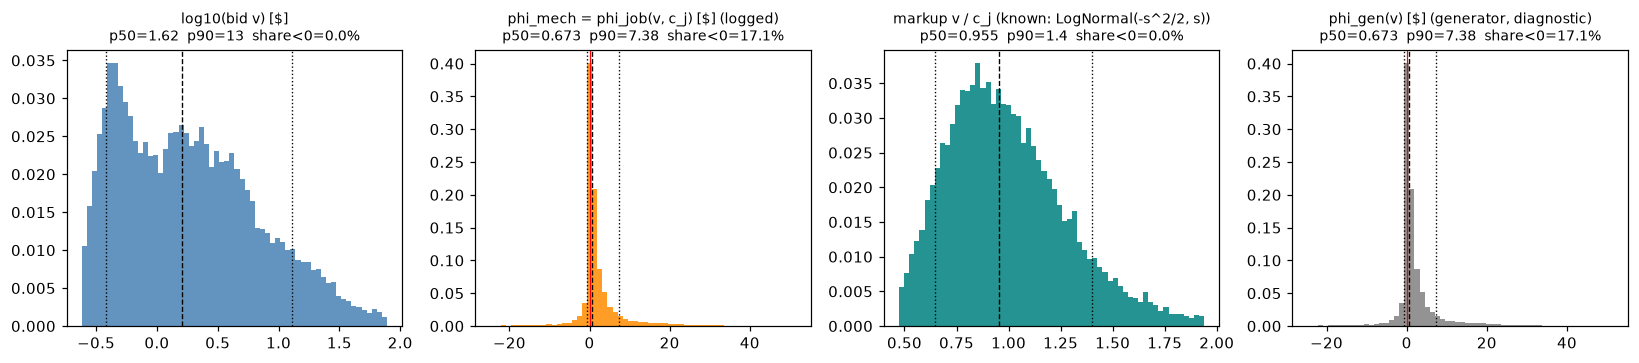

In [9]:
def qhist(ax, x, color, title, w=None, bins=60, logx=False):
    x = np.asarray(x, float)
    w = np.ones_like(x) if w is None else np.asarray(w, float)
    xv = np.log10(np.clip(x, 1e-12, None)) if logx else x
    lo, hi = _weighted_quantile(xv, w, 0.01), _weighted_quantile(xv, w, 0.99)
    ax.hist(xv, bins=bins, range=(lo, hi), weights=w / w.sum(), color=color, alpha=0.85)
    for q, ls in ((0.10, ":"), (0.50, "--"), (0.90, ":")):
        ax.axvline(_weighted_quantile(xv, w, q), color="k", ls=ls, lw=0.9)
    if not logx and lo < 0 < hi:
        ax.axvline(0, color="r", lw=0.8)
    neg = np.average(x < 0, weights=w)
    title = title.replace("$", r"\$")                     # no mathtext between two '$'
    ax.set_title(f"{title}\np50={_weighted_quantile(x, w, .5):.3g}  p90={_weighted_quantile(x, w, .9):.3g}"
                 f"  share<0={100 * neg:.1f}%", fontsize=9)

fig, ax = plt.subplots(1, 4, figsize=(15, 3.4))
qhist(ax[0], A0["v"], C_BID, "log10(bid v) [$]", logx=True)
qhist(ax[1], A0["phi_mech"], C_PI, "phi_mech = phi_job(v, c_j) [$] (logged)")
qhist(ax[2], A0["v"] / S0.cost_base[A0["i"]], "teal", "markup v / c_j (known: LogNormal(-s^2/2, s))")
qhist(ax[3], A0["phi_gen"], "gray", "phi_gen(v) [$] (generator, diagnostic)")
plt.tight_layout(); plt.show()

### 1.b Customer value CV = q·v, Π, C$ = s_C·K: job level (stream) and type level (full-stream reference types, weights p_j)

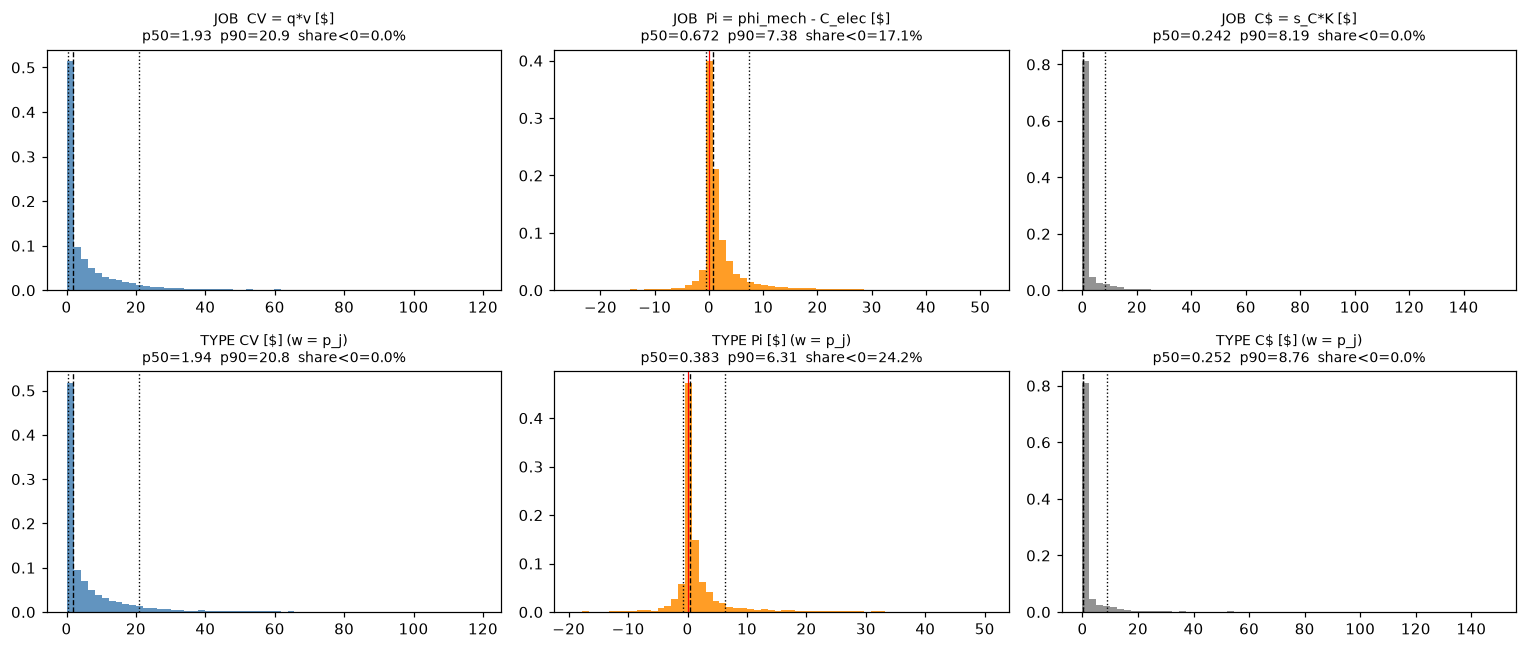

In [10]:
st_ref0 = R0["st_ref"]
_, prio_ref, _ = type_arrays(st_ref0.type_space, st_ref0.grid)
pop = st_ref0.p > 0
wt = st_ref0.p[pop]
CV_t = (prio_ref * st_ref0.v_bar)[pop]
PI_t = (st_ref0.phi_bar - st_ref0.C_elec_bar)[pop]
C_t = SC0 * st_ref0.C_carbon_bar[pop]

fig, ax = plt.subplots(2, 3, figsize=(14, 6))
qhist(ax[0, 0], A0["CV"], C_CV, "JOB  CV = q*v [$]")
qhist(ax[0, 1], A0["PI"], C_PI, "JOB  Pi = phi_mech - C_elec [$]")
qhist(ax[0, 2], A0["Cusd"], C_C, "JOB  C$ = s_C*K [$]")
qhist(ax[1, 0], CV_t, C_CV, "TYPE CV [$] (w = p_j)", w=wt)
qhist(ax[1, 1], PI_t, C_PI, "TYPE Pi [$] (w = p_j)", w=wt)
qhist(ax[1, 2], C_t, C_C, "TYPE C$ [$] (w = p_j)", w=wt)
plt.tight_layout(); plt.show()

desc = []
for lvl, (sw, pi, cu, w) in {"job": (A0["CV"], A0["PI"], A0["Cusd"], None),
                             "type": (CV_t, PI_t, C_t, wt)}.items():
    for name, x in (("CV", sw), ("Pi", pi), ("C$", cu)):
        x = np.asarray(x, float); ww = np.ones_like(x) if w is None else w
        desc.append({"level": lvl, "objective": name, "min": x.min(),
                     **{f"p{int(q * 100)}": _weighted_quantile(x, ww, q) for q in (.01, .1, .5, .9, .99)},
                     "max": x.max(), "share<0 %": 100 * np.average(x < 0, weights=ww)})
display(pd.DataFrame(desc).set_index(["level", "objective"]).style.format(precision=4))

### 1.c Negative base reward R = λ1·CV + λ2·Π − λ3·s_C·K (CV = customer value q·v)

Job level: R_job of every stream arrival (φ of its phase). Type level: r̃ of the state used in each phase, weighted
by that state's p̂ (populated types); "reference" = full-stream types weighted by p_ref. "no carbon" drops −λ3·s_C·K.

In [11]:
neg_rows = [{"level": "job", "scope": "all phases", "n": len(A0),
             "R<0 %": 100 * (A0["R_job"] < 0).mean(), "R<0 no carbon %": 100 * (A0["R_nocarb"] < 0).mean()}]
for m, g in A0.groupby("m"):
    neg_rows.append({"level": "job", "scope": f"phase {m}", "n": len(g),
                     "R<0 %": 100 * (g["R_job"] < 0).mean(),
                     "R<0 no carbon %": 100 * (g["R_nocarb"] < 0).mean()})
for m, st in enumerate(M0.states, start=1):
    pp = st.p > 0
    neg_rows.append({"level": "type", "scope": f"phase {m} state", "n": int(pp.sum()),
                     "R<0 %": 100 * np.average(st.r_tilde[pp] < 0, weights=st.p[pp]),
                     "R<0 no carbon %": 100 * np.average(st.r_nocarbon[pp] < 0, weights=st.p[pp])})
neg_rows.append({"level": "type", "scope": "reference (full stream)", "n": int(pop.sum()),
                 "R<0 %": 100 * np.average(st_ref0.r_tilde[pop] < 0, weights=wt),
                 "R<0 no carbon %": 100 * np.average(st_ref0.r_nocarbon[pop] < 0, weights=wt)})
display(pd.DataFrame(neg_rows).set_index(["level", "scope"]).style.format(precision=2))

neg = A0[A0["R_job"] < 0]
na = neg[neg["admit"]]
print(f"jobs with R_job < 0: {len(neg):,} / {len(A0):,} ({100 * len(neg) / len(A0):.1f}%)  -> admitted: "
      f"{len(na):,} ({100 * len(na) / max(len(neg), 1):.1f}% of the negative ones)")
print("decision of negative-R jobs:", neg["decision"].value_counts().to_dict())
if len(na):
    print("admitted negative-R jobs (the oracle sees the TYPE reward r~, not R_job):")
    print(f"  share with type score r~ - tau^T v > 0      : {100 * (na['score'] > 0).mean():.1f}%")
    print(f"  mean r~_type = {na['r_tilde'].mean():.3f} $   mean R_job = {na['R_job'].mean():.3f} $   "
          f"mean gap R_job - r~ = {(na['R_job'] - na['r_tilde']).mean():.3f} $")
    print(f"  share with Pi_job < 0                        : {100 * (na['PI'] < 0).mean():.1f}%")
    print(f"  share with phi_mech < 0                      : {100 * (na['phi_mech'] < 0).mean():.1f}%")
    print(f"  share with R_job >= 0 without carbon (carbon flips the sign): "
          f"{100 * (na['R_nocarb'] >= 0).mean():.1f}%")
    # job table: the job reward next to the TYPE-level expected reward r~ the oracle used
    JOB_COLS = ["i", "m", "type", "q", "v", "CV", "PI", "Cusd", "R_job", "r_tilde", "shadow_cost", "score", "decision"]
    print("admitted jobs with the most negative R_job (r_tilde = type-level expected reward the oracle saw):")
    display(na.sort_values("R_job")[JOB_COLS].head(15).style.format(precision=3))

jobs with R_job < 0: 2,468 / 15,308 (16.1%)  -> admitted: 403 (16.3% of the negative ones)
decision of negative-R jobs: {'oracle reject': 1769, 'accepted': 403, 'thinning reject': 221, 'physical reject': 75}
admitted negative-R jobs (the oracle sees the TYPE reward r~, not R_job):
  share with type score r~ - tau^T v > 0      : 100.0%
  mean r~_type = 4.782 $   mean R_job = -12.756 $   mean gap R_job - r~ = -17.538 $
  share with Pi_job < 0                        : 95.8%
  share with phi_mech < 0                      : 95.8%
  share with R_job >= 0 without carbon (carbon flips the sign): 16.4%
admitted jobs with the most negative R_job (r_tilde = type-level expected reward the oracle saw):


,i,m,type,q,v,CV,PI,Cusd,R_job,r_tilde,shadow_cost,score,decision
14351,14351,8,7226,1.000,1.948,1.948,-989.563,0.273,-987.888,2.457,0.368,2.089,accepted
12906,12906,6,11539,1.000,12.442,12.442,-474.582,0.398,-462.538,11.893,0.000,11.893,accepted
14333,14333,7,11459,4.000,8.982,35.929,-304.332,5.641,-274.044,31.093,0.650,30.443,accepted
3451,3451,5,8859,2.000,4.780,9.560,-228.340,8.495,-227.274,7.436,0.000,7.436,accepted
11365,11365,6,9382,4.000,5.447,21.786,-196.968,1.990,-177.172,13.207,0.000,13.207,accepted
11884,11884,6,9725,4.000,6.208,24.830,-156.824,1.022,-133.016,29.449,0.000,29.449,accepted
14440,14440,8,16828,1.000,38.203,38.203,-143.639,15.143,-120.579,118.675,50.627,68.048,accepted
11682,11682,6,7142,4.000,2.237,8.946,-110.271,0.906,-102.231,8.379,0.000,8.379,accepted
12044,12044,6,10910,1.000,9.963,9.963,-100.567,0.823,-91.427,14.954,0.000,14.954,accepted
6221,6221,5,9939,1.000,7.328,7.328,-85.666,0.197,-78.535,10.469,0.000,10.469,accepted


## Section 2: Per-phase margin (C.2, baseline scale)

One figure per phase, x = arrival tick (jobs arriving in that phase only). Grey dots: job reward R_job.
Blue line: rolling median of the type reward r̃_type. Purple line: rolling median of the shadow-price cost τᵀv_type.
Markers: margin r̃_type − τᵀv_type by final decision. Black line: rolling median of the margin, shaded green
where > 0 and red where < 0. y axis: symlog (linear within ±1 $). Phases with more than `N_PLOT` arrivals are
randomly subsampled to `N_PLOT` points (fixed seed); rolling medians use every arrival of the phase.

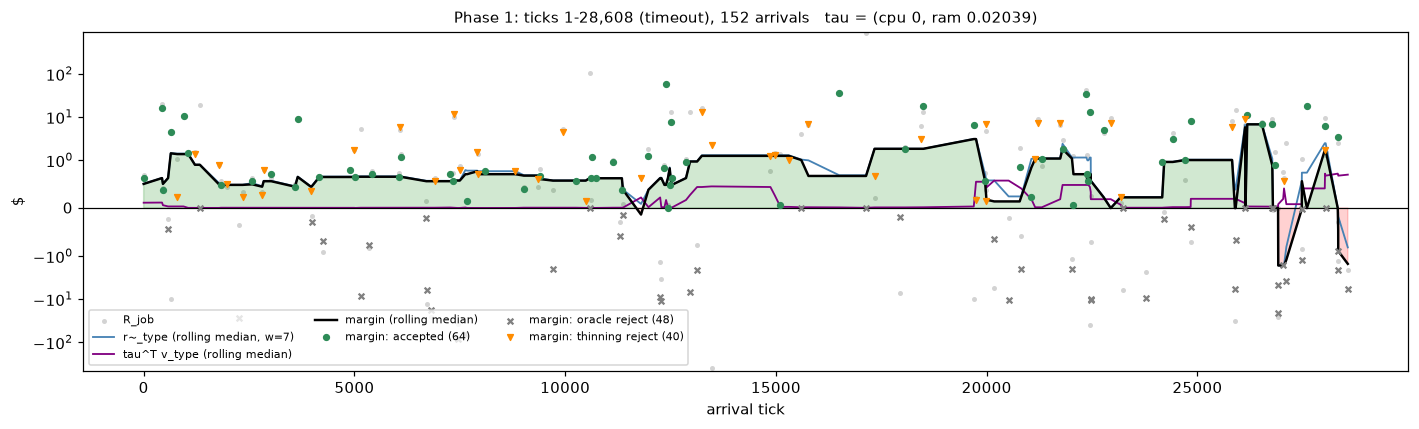

phase 1: share margin>0 = 68.4%   median margin = 0.614 $


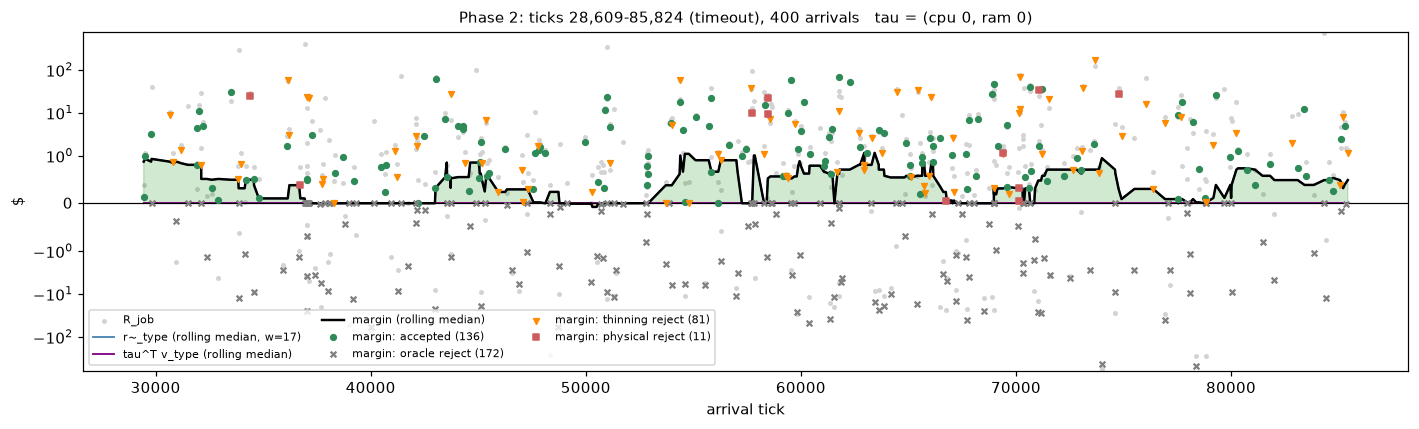

phase 2: share margin>0 = 57.0%   median margin = 0.306 $   (tau = 0: shadow cost = 0, margin = r~_type)


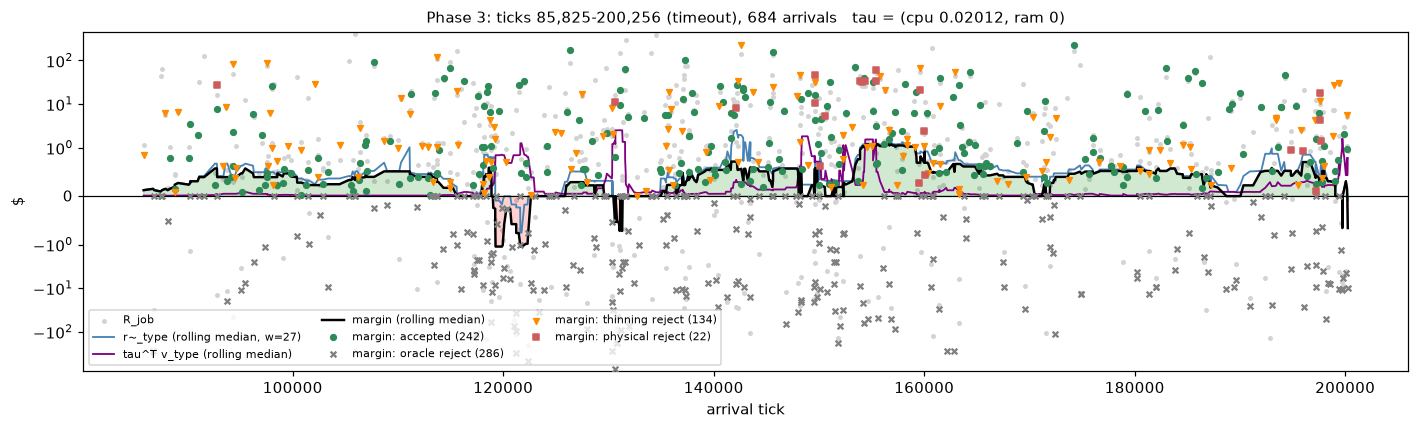

phase 3: share margin>0 = 58.2%   median margin = 0.326 $


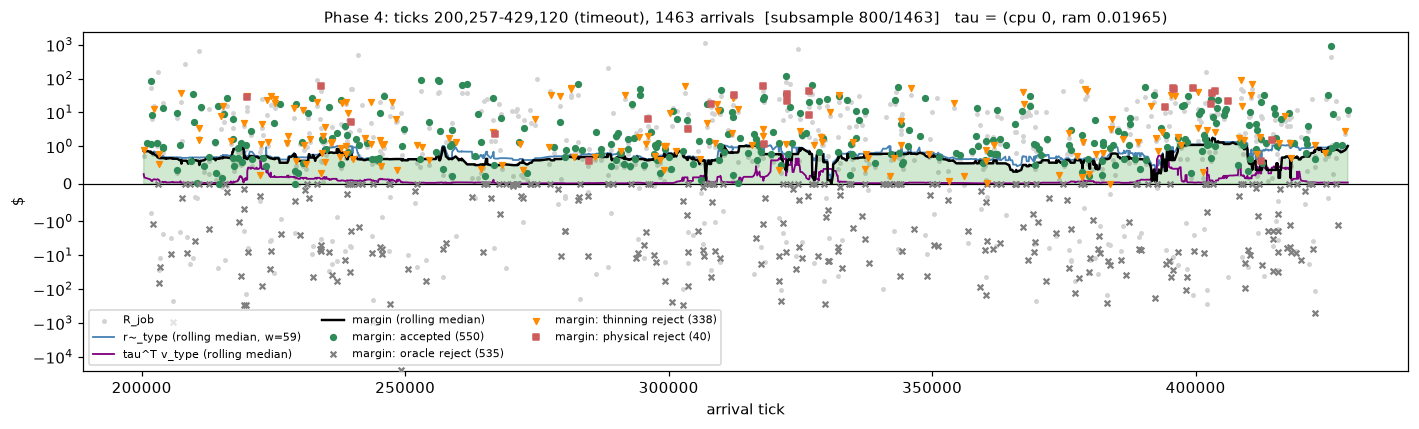

phase 4: share margin>0 = 63.4%   median margin = 0.693 $


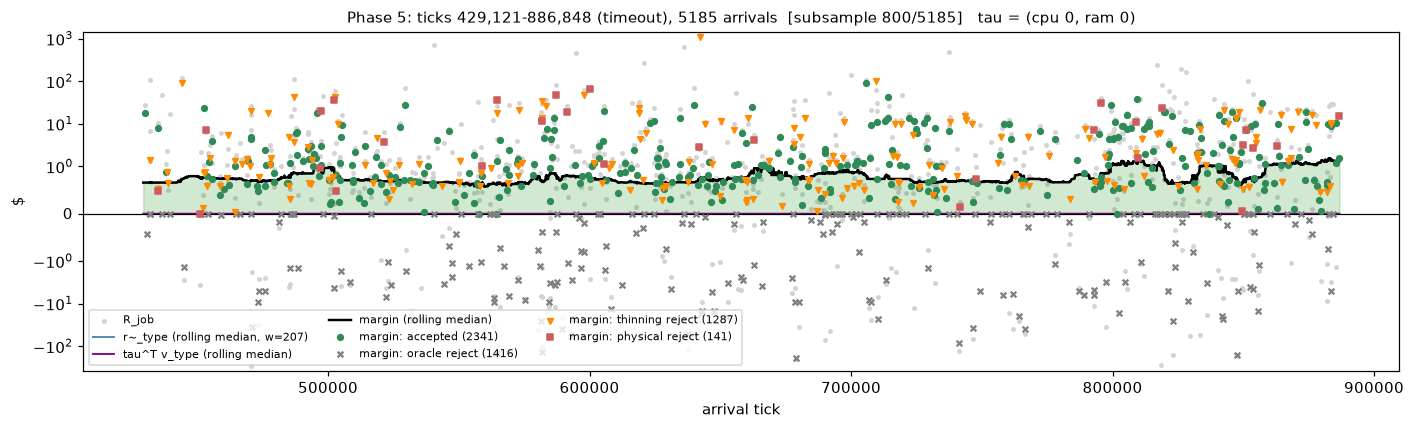

phase 5: share margin>0 = 72.7%   median margin = 0.740 $   (tau = 0: shadow cost = 0, margin = r~_type)


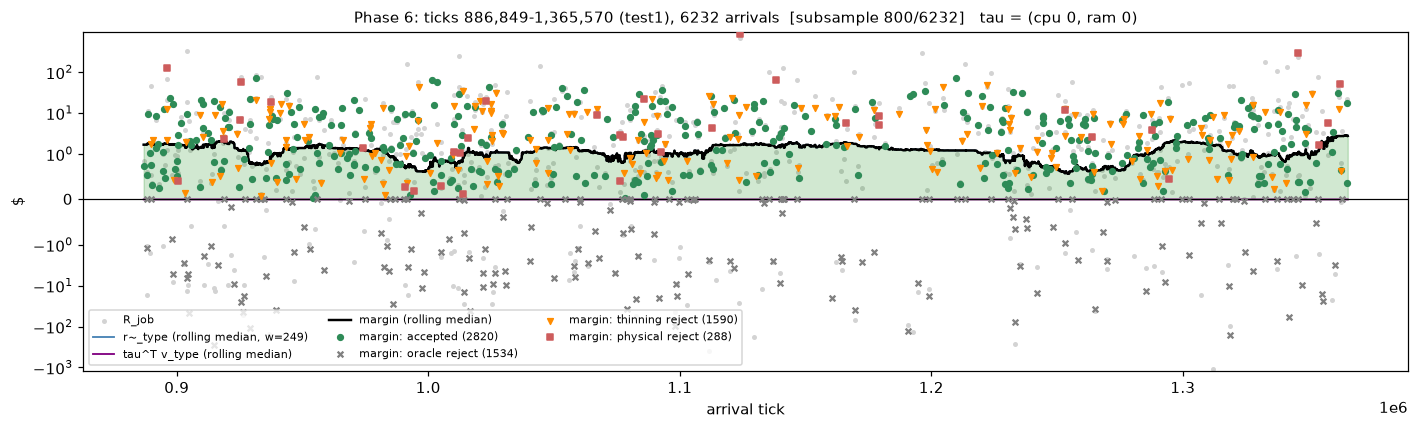

phase 6: share margin>0 = 75.4%   median margin = 1.117 $   (tau = 0: shadow cost = 0, margin = r~_type)


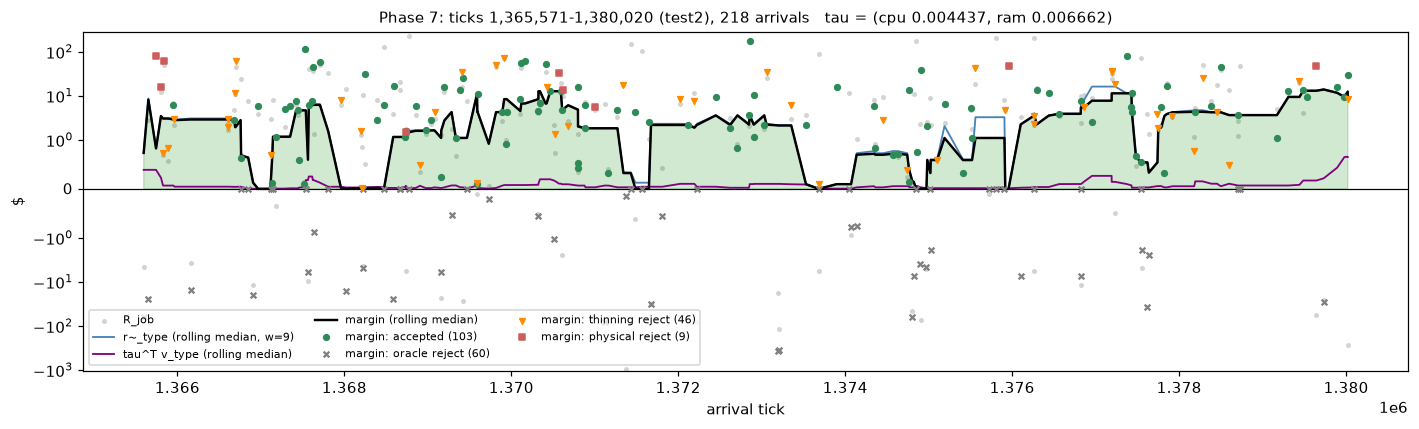

phase 7: share margin>0 = 72.5%   median margin = 2.152 $


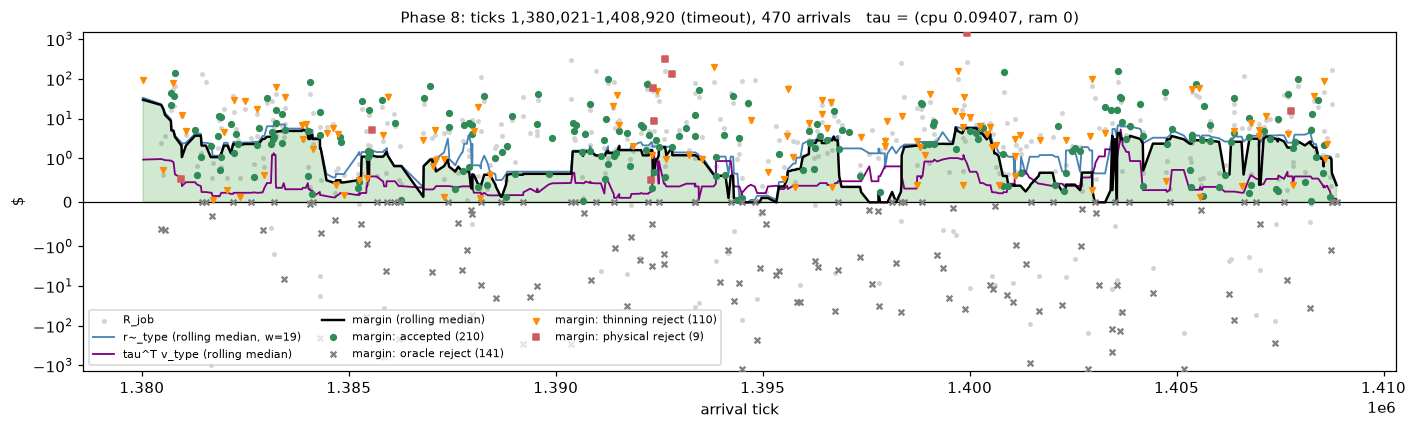

phase 8: share margin>0 = 70.0%   median margin = 1.175 $


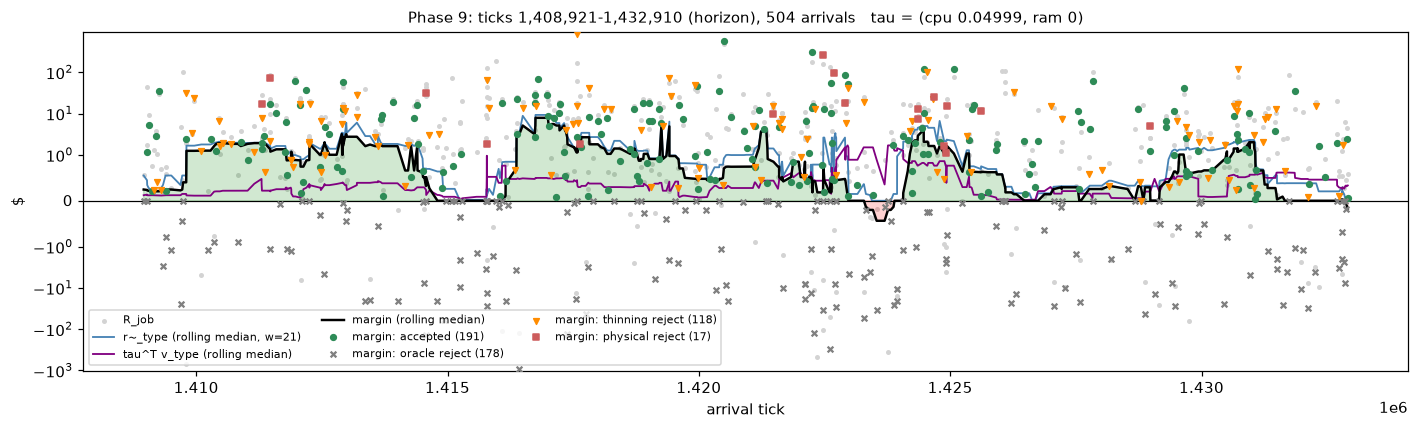

phase 9: share margin>0 = 64.7%   median margin = 0.627 $


In [12]:
N_PLOT = 800
for m, g_all in A0.groupby("m"):
    p = PH0[PH0["m"] == m].iloc[0]
    st = M0.states[m - 1]
    g_all = g_all.sort_values("t")
    w = max(5, len(g_all) // 25) | 1
    roll = lambda col: g_all[col].rolling(w, center=True, min_periods=1).median()
    rm_r, rm_s, rm_m = roll("r_tilde"), roll("shadow_cost"), roll("score")
    g = g_all.sample(N_PLOT, random_state=0).sort_values("t") if len(g_all) > N_PLOT else g_all
    fig, ax = plt.subplots(figsize=(13, 4))
    ax.scatter(g["t"], g["R_job"], s=5, color="lightgray", label="R_job", zorder=1)
    ax.plot(g_all["t"], rm_r, color="steelblue", lw=1.2, label=f"r~_type (rolling median, w={w})")
    ax.plot(g_all["t"], rm_s, color="purple", lw=1.2, label="tau^T v_type (rolling median)")
    ax.plot(g_all["t"], rm_m, color="k", lw=1.6, label="margin (rolling median)")
    mm = rm_m.to_numpy()
    ax.fill_between(g_all["t"], 0, mm, where=mm > 0, color="green", alpha=0.18, interpolate=True)
    ax.fill_between(g_all["t"], 0, mm, where=mm < 0, color="red", alpha=0.18, interpolate=True)
    for d in DEC_ORDER:
        h = g[g["decision"] == d]
        if len(h):
            col, mk = DEC_STYLE[d]
            ax.scatter(h["t"], h["score"].replace(-np.inf, np.nan), s=14, color=col, marker=mk,
                       label=f"margin: {d} ({(g_all['decision'] == d).sum()})", zorder=3)
    ax.axhline(0, color="k", lw=0.8)
    ax.set_yscale("symlog", linthresh=1.0)
    ax.set_xlabel("arrival tick"); ax.set_ylabel("$")
    sub = f"  [subsample {len(g)}/{len(g_all)}]" if len(g) < len(g_all) else ""
    ax.set_title(f"Phase {m}: ticks {p['tau_start']:,}-{p['tau_end']:,} ({p['reason']}), {len(g_all)} arrivals{sub}"
                 f"   tau = (cpu {st.tau[0]:.4g}, ram {st.tau[1]:.4g})", fontsize=10)
    ax.legend(fontsize=7, ncol=3, loc="lower left")
    plt.tight_layout(); plt.show()
    zero_tau = np.allclose(st.tau, 0)
    print(f"phase {m}: share margin>0 = {100 * (g_all['score'] > 0).mean():.1f}%   "
          f"median margin = {np.nanmedian(g_all['score'].replace(-np.inf, np.nan)):.3f} $"
          + ("   (tau = 0: shadow cost = 0, margin = r~_type)" if zero_tau else ""))

## Section 3: Results per phase (C.3, baseline scale)

Rejections by reason: IR (no type), oracle (r̃ − τᵀv ≤ 0), thinning (oracle yes, U(t) = 0), physical
(oracle yes, U(t) = 1, U + A > c). Reward = logged dollars; its three parts are λ1·CV, λ2·Π and −λ3·s_C·K of the
admitted jobs (they sum to the total). Occupancy = exact step function from the event log (heap releases), as a
fraction of the current capacity, time-weighted over the phase's ticks.

In [13]:
def phase_table(run):
    a, ph, model = run["A"], run["ph"], run["model"]
    c = model.c
    rows = []
    for _, p in ph.iterrows():
        m = int(p["m"]); g = a[a["m"] == m]; adm = g[g["admit"]]
        mean, peak = occ_stats(run["te"], run["Ue"], int(p["tau_start"]), int(p["tau_end"]))
        st = model.states[m - 1]
        # cross-check against the loop's own per-phase counters
        assert (g["decision"] == "thinning reject").sum() == p["n_thinned"]
        assert (g["decision"] == "physical reject").sum() == p["n_phys_reject"]
        assert len(adm) == p["n_admitted"] and np.isclose(adm["R"].sum(), p["R"])
        rows.append({
            "phase": m, "start": int(p["tau_start"]), "end": int(p["tau_end"]), "steps": int(p["W"]),
            "jobs": len(g), "end reason": p["reason"], "admitted": len(adm),
            "rej IR": int((g["decision"] == "IR reject").sum()),
            "rej oracle": int((g["decision"] == "oracle reject").sum()),
            "rej thinning": int((g["decision"] == "thinning reject").sum()),
            "rej physical": int((g["decision"] == "physical reject").sum()),
            "adm rate %": 100 * len(adm) / max(len(g), 1),
            "R $": adm["R"].sum(), "l1*CV $": L1 * adm["CV"].sum(), "l2*Pi $": L2 * adm["PI"].sum(),
            "-l3*s_C*K $": -L3 * adm["Cusd"].sum(),
            "adm R<0": int((adm["R"] < 0).sum()), "adm R<0 %": 100 * (adm["R"] < 0).mean() if len(adm) else 0.0,
            "occ cpu mean %": 100 * mean[0] / c[0], "occ ram mean %": 100 * mean[1] / c[1],
            "occ cpu peak %": 100 * peak[0] / c[0], "occ ram peak %": 100 * peak[1] / c[1],
            "tau_cpu start": st.tau[0], "tau_ram start": st.tau[1],
        })
    df = pd.DataFrame(rows).set_index("phase")
    tot = df.sum(numeric_only=True)
    g = run["A"]; adm = g[g["admit"]]
    mean, peak = occ_stats(run["te"], run["Ue"], 1, int(model.ds.T))
    tot.update({"start": 1, "end": int(model.ds.T), "adm rate %": 100 * len(adm) / len(g),
                "adm R<0 %": 100 * (adm["R"] < 0).mean(), "occ cpu mean %": 100 * mean[0] / c[0],
                "occ ram mean %": 100 * mean[1] / c[1], "occ cpu peak %": 100 * peak[0] / c[0],
                "occ ram peak %": 100 * peak[1] / c[1], "tau_cpu start": np.nan, "tau_ram start": np.nan})
    df.loc["total"] = tot
    df.loc["total", "end reason"] = ""
    return df

PT0 = phase_table(R0)
display(PT0.style.format(precision=3))
assert np.isclose(PT0.loc["total", "R $"], R0["res"].summary["R_total"])

,start,end,steps,jobs,end reason,admitted,rej IR,rej oracle,rej thinning,rej physical,adm rate %,R $,l1*CV $,l2*Pi $,-l3*s_C*K $,adm R<0,adm R<0 %,occ cpu mean %,occ ram mean %,occ cpu peak %,occ ram peak %,tau_cpu start,tau_ram start
phase,,,,,,,,,,,,,,,,,,,,,,,
1,1.000,28608.000,28608.000,152.000,timeout,64.000,0.000,48.000,40.000,0.000,42.105,254.160,239.656,49.710,-35.207,3.000,4.688,9.725,8.503,71.021,75.881,0.000,0.020
2,28609.000,85824.000,57216.000,400.000,timeout,136.000,0.000,172.000,81.000,11.000,34.000,809.639,649.038,270.420,-109.819,4.000,2.941,16.775,16.720,96.125,93.824,0.000,0.000
3,85825.000,200256.000,114432.000,684.000,timeout,242.000,0.000,286.000,134.000,22.000,35.380,1930.986,1518.082,582.483,-169.579,11.000,4.545,12.751,14.394,88.289,99.399,0.020,0.000
4,200257.000,429120.000,228864.000,1463.000,timeout,550.000,0.000,535.000,338.000,40.000,37.594,2833.816,2693.449,666.243,-525.876,44.000,8.000,19.903,22.784,98.483,98.800,0.000,0.020
5,429121.000,886848.000,457728.000,5185.000,timeout,2341.000,0.000,1416.000,1287.000,141.000,45.149,11868.451,10257.431,2790.693,-1179.673,140.000,5.980,23.056,21.520,99.725,99.655,0.000,0.000
6,886849.000,1365570.000,478722.000,6232.000,test1,2820.000,0.000,1534.000,1590.000,288.000,45.250,19567.576,17874.784,3444.075,-1751.283,172.000,6.099,30.069,26.846,99.735,99.902,0.000,0.000
7,1365571.000,1380020.000,14450.000,218.000,test2,103.000,0.000,60.000,46.000,9.000,47.248,764.164,1013.442,-181.730,-67.548,7.000,6.796,39.690,28.208,99.682,99.902,0.004,0.007
8,1380021.000,1408920.000,28900.000,470.000,timeout,210.000,0.000,141.000,110.000,9.000,44.681,500.150,1414.972,-792.442,-122.380,15.000,7.143,34.618,23.195,99.690,93.718,0.094,0.000
9,1408921.000,1432910.000,23990.000,504.000,horizon,191.000,0.000,178.000,118.000,17.000,37.897,2363.198,1972.341,488.197,-97.339,7.000,3.665,32.700,24.788,99.956,83.845,0.050,0.000


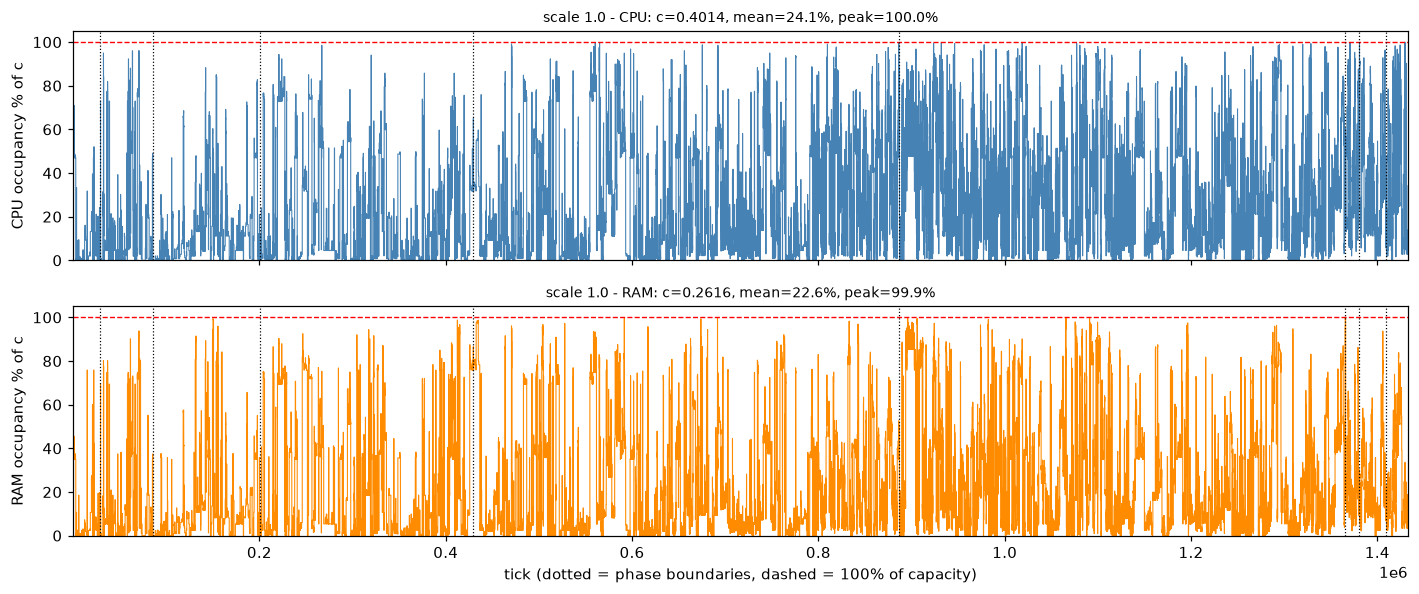

In [14]:
def plot_occupancy(ax_cpu, ax_ram, run, title=""):
    model = run["model"]; c = model.c; T = int(model.ds.T)
    te, Ue = run["te"], run["Ue"]
    x = np.r_[1, te, T]
    for ax, i, col, name in ((ax_cpu, 0, C_CPU, "CPU"), (ax_ram, 1, C_RAM, "RAM")):
        y = 100 * np.r_[0.0, Ue[:, i], Ue[-1, i]] / c[i]
        ax.step(x, y, where="post", color=col, lw=0.7)
        ax.axhline(100, color="red", ls="--", lw=0.9)
        for b in run["ph"]["tau_start"].iloc[1:]:
            ax.axvline(b, color="k", ls=":", lw=0.8)
        ax.set_ylim(0, 105); ax.set_xlim(1, T)
        ax.set_ylabel(f"{name} occupancy % of c")
        ax.set_title(f"{title}{name}: c={c[i]:.4g}, mean={100 * np.average(Ue[:-1, i], weights=np.diff(te)) / c[i] if len(te) > 1 else 0:.1f}%"
                     f", peak={100 * Ue[:, i].max() / c[i]:.1f}%", fontsize=9)

fig, ax = plt.subplots(2, 1, figsize=(13, 5.5), sharex=True)
plot_occupancy(ax[0], ax[1], R0, title=f"scale {BASELINE_SCALE} - ")
ax[1].set_xlabel("tick (dotted = phase boundaries, dashed = 100% of capacity)")
plt.tight_layout(); plt.show()

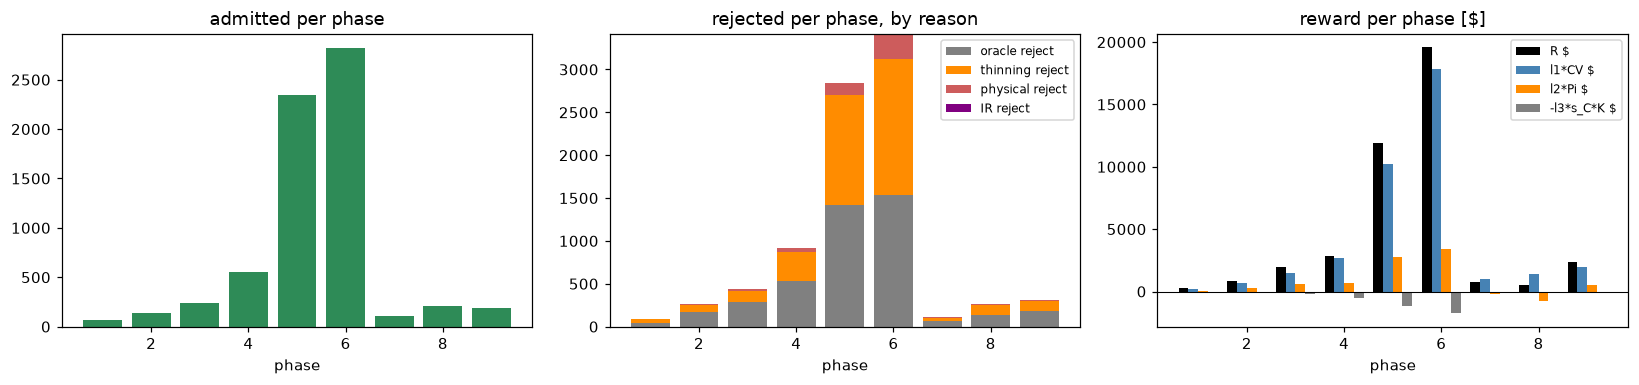

In [15]:
body = PT0.drop(index="total")
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
idx = body.index.astype(int)
ax[0].bar(idx, body["admitted"], color="seagreen")
ax[0].set_title("admitted per phase"); ax[0].set_xlabel("phase")
bottom = np.zeros(len(body))
for col, d in (("rej oracle", "oracle reject"), ("rej thinning", "thinning reject"),
               ("rej physical", "physical reject"), ("rej IR", "IR reject")):
    ax[1].bar(idx, body[col], bottom=bottom, color=DEC_STYLE[d][0], label=d)
    bottom += body[col].to_numpy(float)
ax[1].legend(fontsize=8); ax[1].set_title("rejected per phase, by reason"); ax[1].set_xlabel("phase")
wb = 0.2
for k, (col, cc) in enumerate((("R $", "k"), ("l1*CV $", C_CV), ("l2*Pi $", C_PI), ("-l3*s_C*K $", C_C))):
    ax[2].bar(idx + (k - 1.5) * wb, body[col], width=wb, color=cc, label=col)
ax[2].axhline(0, color="k", lw=0.7); ax[2].legend(fontsize=8); ax[2].set_title("reward per phase [$]")
ax[2].set_xlabel("phase")
plt.tight_layout(); plt.show()

## Section 4: Accuracy per phase (C.4, baseline scale)

**All references are ORACLE quantities** (full stream, true labels; not available online). Phase k runs with the
state built at the end of phase k−1 (phase 1: Phase 0 on H). Because the valuation grid is refit at every phase,
each comparison is done **on phase k's own type space**: the full stream is re-assigned to phase k's types to
build p_ref, d_ref and r_ref (with φ_ref, s_C frozen).

* TV(p̂_k, p_ref): both normalised to sum 1 over types; thin mass = p_ref mass of types with N_j < n_type_min in the
  data that built the state.
* d̂ error: |d̂ − d_ref| / d_ref over types with p_ref > 0 (p_ref-weighted mean and median). CI: 95% normal half-width
  1.96·sd/√M of the observed durations that built the state, relative to their mean, over types with M ≥ 2.
* KS(F̂_k, F_emp): the phase's bid model F̂_k vs the empirical CDF of all stream MARKUPS m = v / c_j. Under the known
  distribution F̂_k = LogNormal(−σ²/2, σ) in every phase (never refit), so this measures the fit of the configured
  markup distribution, not learning. φ error: mean |φ_k(v) − φ(v)|, 0 by construction with one known φ.
* reward error: p_ref-weighted mean |r̃_k − r_ref| ($ and relative to mean |r_ref|), and the share of
  **decision errors due to discretization**: types where sign(r̃_k) ≠ sign(r_ref), i.e. the phase's type reward
  would admit (reject) a type the full-stream type reward rejects (admits).
* ‖τ̂_k − τ*‖ with τ* the dual of the full-stream hindsight LP.
* decision agreement: share of phase-k arrivals where k̂ (phase oracle) equals the hindsight oracle
  1[r_ref − τ*ᵀv_ref > 0] on the reference types; also vs the offline job-level OPT x*.
* theory (error_params.py, Appendix A): ε_D, η(W_prev), p_U at the phase start/end, CI¹(W), ε̃_Test2(W), ε_Test3(W).

In [16]:
def accuracy_table(run):
    model, a, ph, st_ref = run["model"], run["A"], run["ph"], run["st_ref"]
    S, ds, ep = model.stream, model.ds, model.ep
    nmin = BASE.phase_transition.n_type_min
    phi_ref = run["J"]["phi"]                                     # the one known phi
    m_sorted = np.sort(S.v / S.cost_base); n = S.n                # markups, the known model's variable
    e_hi, e_lo = np.arange(1, n + 1) / n, np.arange(n) / n
    rows = []
    for k, st in enumerate(model.states, start=1):
        nT = st.n_types
        tid = types_under(st, S); ok = tid >= 0
        N_ref = np.bincount(tid[ok], minlength=nT).astype(float)
        p_ref = N_ref / N_ref.sum()
        p_hat = st.p / st.p.sum()
        if k == 1:
            W_used, n_used = ds.H_span_steps, ds.H.n
            H = ds.H
            tid_o = assign_type_ids(st.type_space, st.grid.assign(st.bids.v_rate, st.myerson), H.priority, H.hw_idx)
            D_o = H.duration_steps
        else:
            prev = ph[ph["m"] == k - 1].iloc[0]
            W_used, n_used = int(prev["W"]), int(prev["n_arrivals"])
            obs = a.loc[(a["m"] == k - 1) & a["admit"], "i"].to_numpy()
            tid_o, D_o = types_under(st, S, obs), S.D[obs]
        N_used = np.rint(st.p * W_used)
        mean_by = lambda x: np.divide(np.bincount(tid[ok], weights=np.asarray(x, float)[ok], minlength=nT),
                                      N_ref, out=np.zeros(nT), where=N_ref > 0)
        d_ref = mean_by(S.D)
        mk = p_ref > 0
        rel_d = np.abs(st.d_bar[mk] - d_ref[mk]) / d_ref[mk]
        oo = tid_o >= 0
        M = np.bincount(tid_o[oo], minlength=nT).astype(float)
        s1 = np.bincount(tid_o[oo], weights=D_o[oo].astype(float), minlength=nT)
        s2 = np.bincount(tid_o[oo], weights=D_o[oo].astype(float) ** 2, minlength=nT)
        mu = np.divide(s1, M, out=np.zeros(nT), where=M > 0)
        var = np.divide(s2 - M * mu ** 2, M - 1, out=np.zeros(nT), where=M > 1)
        ci = np.divide(1.96 * np.sqrt(np.clip(var, 0, None) / np.maximum(M, 1)), mu,
                       out=np.full(nT, np.nan), where=(M > 1) & (mu > 0))
        mc = mk & np.isfinite(ci)
        assert st.myerson.known, "KS on markups assumes bid.known_distribution"
        F_hat = lognorm.cdf(m_sorted, s=st.myerson.sigma, scale=np.exp(st.myerson.mu))
        ks = max(np.abs(F_hat - e_hi).max(), np.abs(F_hat - e_lo).max())
        phi_k = np.asarray(st.myerson.phi_job(S.v, S.cost_base))
        _, prio, A_t = type_arrays(st.type_space, st.grid)
        r_ref, *_ = type_reward(prio, mean_by(S.v), mean_by(phi_ref), mean_by(S.C_elec), mean_by(S.C_carbon),
                                p_ref, BASE, s_C=model.state0.carbon_price)
        w = p_ref[mk]
        r_err = np.average(np.abs(st.r_tilde[mk] - r_ref[mk]), weights=w)
        g = a[a["m"] == k]
        W = int(ph.loc[ph["m"] == k, "W"].iloc[0]); W_prev = int(ph.loc[ph["m"] == k, "W_prev"].iloc[0])
        rows.append({
            "phase": k, "n used (arrivals)": n_used, "built from": "H (Phase 0)" if k == 1 else f"phase {k - 1}",
            "TV(p_hat,p_ref)": 0.5 * np.abs(p_hat - p_ref).sum(),
            "thin mass (N_j<n_type_min)": p_ref[N_used < nmin].sum(),
            "d rel err mean": np.average(rel_d, weights=w),
            "d rel err median": _weighted_quantile(rel_d, w, 0.5),
            "d CI rel half-width": np.average(ci[mc], weights=p_ref[mc]) if mc.any() else np.nan,
            "d CI mass covered": p_ref[mc].sum(),
            "KS(F_hat,F_emp)": ks,
            "phi mean abs err $": np.mean(np.abs(phi_k - phi_ref)),
            "phi rel err": np.mean(np.abs(phi_k - phi_ref)) / np.mean(np.abs(phi_ref)),
            "r mean abs err $": r_err,
            "r rel err": r_err / np.average(np.abs(r_ref[mk]), weights=w),
            "decision errors (discretization)": np.average(np.sign(st.r_tilde[mk]) != np.sign(r_ref[mk]), weights=w),
            "||tau_k - tau*||": float(np.linalg.norm(st.tau - st_ref.tau)),
            "agree hindsight oracle": (g["k_hat"] == g["k_hat_ref"]).mean(),
            "agree offline x*": (g["k_hat"].to_numpy() == run["opt"]["x"][g["i"].to_numpy()]).mean(),
            "eps_D": ep.eps_D, "eta(W_prev)": float(ep.eta(W_prev)),
            "p_U start": ep.p_U(W_prev, 1), "p_U end": ep.p_U(W_prev, W),
            "CI1(W)": float(ep.CI1(W)), "eps_Test2(W)": float(ep.eps_test2(W_prev, W)),
            "eps_Test3(W)": float(ep.eps_test3(W)),
            "max(Test2 lhs - thr)": float((g["test2_lhs"] - g["test2_thr"]).max()) if "test2_lhs" in g else np.nan,
            "min Test3 screen margin": float(g["test3_screen_margin"].min()) if "test3_screen_margin" in g else np.nan,
        })
    return pd.DataFrame(rows).set_index("phase")

ACC0 = accuracy_table(R0)
display(ACC0.T.style.format(precision=4))

phase,1,2,3,4,5,6,7,8,9
n used (arrivals),10000,152,400,684,1463,5185,6232,218,470
built from,H (Phase 0),phase 1,phase 2,phase 3,phase 4,phase 5,phase 6,phase 7,phase 8
"TV(p_hat,p_ref)",0.4159,0.8744,0.7554,0.6690,0.5170,0.2491,0.2333,0.8873,0.7756
thin mass (N_j<n_type_min),0.5917,1.0000,1.0000,1.0000,0.9341,0.5856,0.5741,1.0000,1.0000
d rel err mean,0.3106,0.3480,0.3605,0.4567,0.3502,0.2714,0.2918,0.4205,0.3932
d rel err median,0.1523,0.2177,0.1870,0.2745,0.2114,0.1192,0.1117,0.1755,0.1776
d CI rel half-width,0.1824,0.1989,0.1627,0.1198,0.1456,0.1959,0.2053,0.1030,0.2686
d CI mass covered,0.6791,0.0135,0.0095,0.0550,0.1483,0.4564,0.5003,0.0042,0.0255
"KS(F_hat,F_emp)",0.0067,0.0067,0.0067,0.0067,0.0067,0.0067,0.0067,0.0067,0.0067
phi mean abs err $,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000


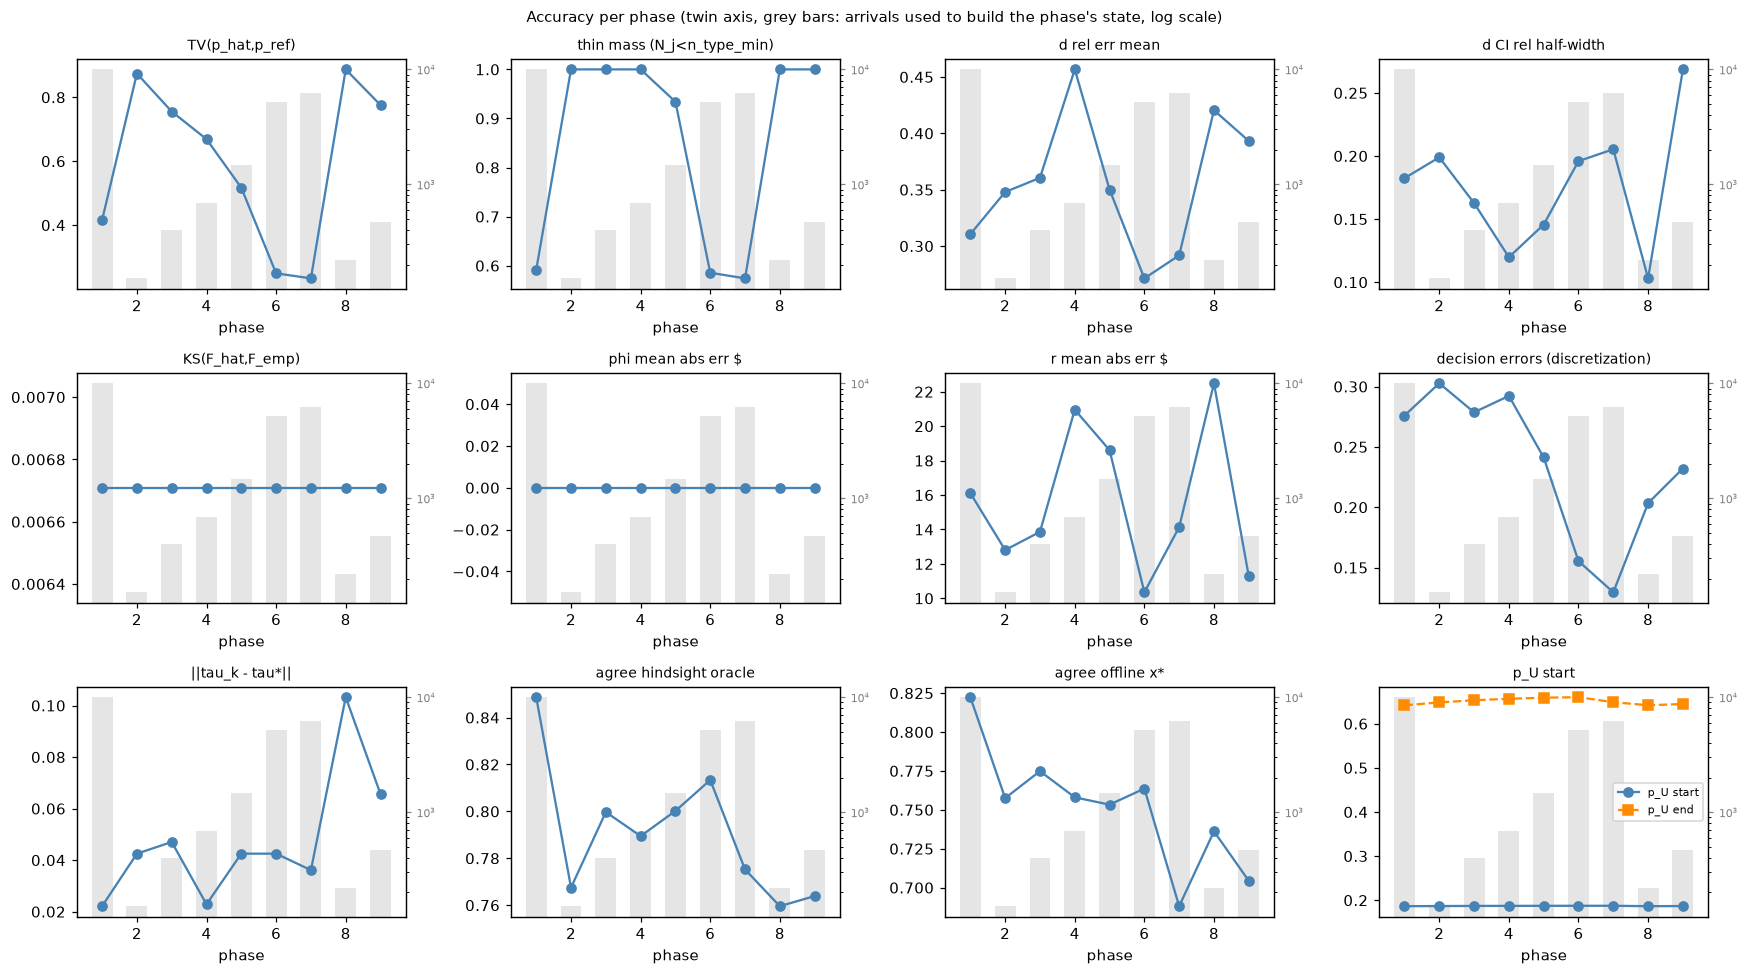

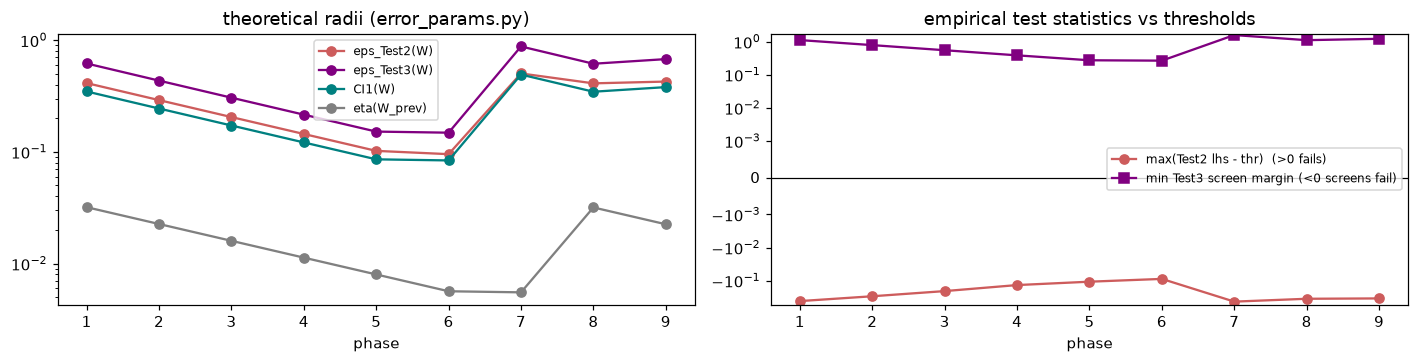

In [17]:
METRICS = ["TV(p_hat,p_ref)", "thin mass (N_j<n_type_min)", "d rel err mean", "d CI rel half-width",
           "KS(F_hat,F_emp)", "phi mean abs err $", "r mean abs err $", "decision errors (discretization)",
           "||tau_k - tau*||", "agree hindsight oracle", "agree offline x*", "p_U start"]
fig, axes = plt.subplots(3, 4, figsize=(16, 9))
for ax, met in zip(axes.ravel(), METRICS):
    ax.plot(ACC0.index, ACC0[met], "o-", color="steelblue", label=met)
    ax.set_title(met, fontsize=9); ax.set_xlabel("phase")
    tw = ax.twinx()
    tw.bar(ACC0.index, ACC0["n used (arrivals)"], color="gray", alpha=0.2, width=0.6)
    tw.set_yscale("log"); tw.tick_params(labelsize=7, colors="gray")
    if met == "p_U start":
        ax.plot(ACC0.index, ACC0["p_U end"], "s--", color="darkorange", label="p_U end")
        ax.legend(fontsize=7)
    ax.set_zorder(tw.get_zorder() + 1); ax.patch.set_visible(False)
fig.suptitle("Accuracy per phase (twin axis, grey bars: arrivals used to build the phase's state, log scale)",
             fontsize=10)
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(13, 3.4))
for col, cc in (("eps_Test2(W)", "indianred"), ("eps_Test3(W)", "purple"), ("CI1(W)", "teal"),
                ("eta(W_prev)", "gray")):
    ax[0].plot(ACC0.index, ACC0[col], "o-", color=cc, label=col)
ax[0].set_yscale("log"); ax[0].legend(fontsize=8); ax[0].set_title("theoretical radii (error_params.py)")
ax[0].set_xlabel("phase")
ax[1].plot(ACC0.index, ACC0["max(Test2 lhs - thr)"], "o-", color="indianred", label="max(Test2 lhs - thr)  (>0 fails)")
ax[1].plot(ACC0.index, ACC0["min Test3 screen margin"], "s-", color="purple", label="min Test3 screen margin (<0 screens fail)")
ax[1].axhline(0, color="k", lw=0.8); ax[1].set_yscale("symlog", linthresh=1e-3); ax[1].legend(fontsize=8)
ax[1].set_title("empirical test statistics vs thresholds"); ax[1].set_xlabel("phase")
plt.tight_layout(); plt.show()

In [18]:
def verdict(df, cols, lower_is_better=True):
    out = []
    for c in cols:
        x = df[c].to_numpy(float)
        d = np.diff(x) if lower_is_better else -np.diff(x)
        d2 = d[1:]
        out.append({"metric": c, "direction checked": "decrease" if lower_is_better else "increase",
                    "phase 1": x[0], "last phase": x[-1],
                    "monotone (all phases)": "yes" if np.all(d <= 1e-12) else "no",
                    "monotone (phases >= 2)": ("yes" if np.all(d2 <= 1e-12) else "no") if len(d2) else "n/a",
                    "last < first": "yes" if (x[-1] < x[0] if lower_is_better else x[-1] > x[0]) else "no"})
    return pd.DataFrame(out).set_index("metric")

V0 = pd.concat([
    verdict(ACC0, ["TV(p_hat,p_ref)", "thin mass (N_j<n_type_min)", "d rel err mean", "d rel err median",
                   "KS(F_hat,F_emp)", "phi mean abs err $", "r mean abs err $", "r rel err", "decision errors (discretization)",
                   "||tau_k - tau*||"]),
    verdict(ACC0, ["agree hindsight oracle", "agree offline x*"], lower_is_better=False),
])
display(V0.style.format(precision=4))
print(f"metrics monotone over all phases: {(V0['monotone (all phases)'] == 'yes').sum()} / {len(V0)};  "
      f"over phases >= 2: {(V0['monotone (phases >= 2)'] == 'yes').sum()} / {len(V0)};  "
      f"last better than phase 1: {(V0['last < first'] == 'yes').sum()} / {len(V0)}")

,direction checked,phase 1,last phase,monotone (all phases),monotone (phases >= 2),last < first
metric,,,,,,
"TV(p_hat,p_ref)",decrease,0.4159,0.7756,no,no,no
thin mass (N_j<n_type_min),decrease,0.5917,1.0000,no,no,no
d rel err mean,decrease,0.3106,0.3932,no,no,no
d rel err median,decrease,0.1523,0.1776,no,no,no
"KS(F_hat,F_emp)",decrease,0.0067,0.0067,yes,yes,no
phi mean abs err $,decrease,0.0000,0.0000,yes,yes,no
r mean abs err $,decrease,16.1101,11.2796,no,no,yes
r rel err,decrease,1.2120,0.8453,no,no,yes
decision errors (discretization),decrease,0.2760,0.2321,no,no,yes


metrics monotone over all phases: 2 / 12;  over phases >= 2: 2 / 12;  last better than phase 1: 3 / 12


## Section 5: Baselines and regret (C.5, theoretical setting: true duration known at arrival)

* **DLENT-RT (online)**: the run above. R = Σ R_job over its admitted set (= the logged reward, asserted).
Scores, benchmarks and regrets come from `dlent_rt.benchmarks` (`score`, `fluid_opt`, `job_level_opt`, `regret`),
in $ over the whole stream.
* **R_OPT fluid**: `fluid_opt()` = λ̂_ref · T, the full-stream LP-RS (`summary["bench_global"]`). It is a per-tick
  fluid quantity on TYPE means, not a feasible schedule.
* **R_OPT offline job-level (ORACLE)**: `job_level_opt()` (LP relaxation and no-capacity sum shown as upper bounds).
* **static τ* (full stream, ORACLE)**: `StaticPolicy` of (r_ref, τ*, v_ref), computed once; same event-driven loop
  (`policy.simulate`), oracle and physical gate as DLENT-RT; no thinning, no learning, no restarts.
* **static Phase 0 (H)**: (r̃, τ, v) of Phase 0 (from H), never updated; no thinning.
* **static Phase 0 (H) + thinning at cap**: same, with U(t) ~ Bern((1 − ξ)/(1 + ε_D)), same random numbers as the
  online run (isolates the thinning effect from learning).
* **G1 (type greedy)**: `TypeGreedyPolicy`, admit iff r̃_j > 0 for the arrival's Phase-0 type; r̃_j starts at Phase 0's
  value and is the cumulative running mean of R_job over H and every stream arrival seen so far (admitted or not;
  this uses the realised R_job of rejected jobs). Unseen types are rejected. No τ, LP, thinning or phases.
* **G2 (job greedy)**: `JobGreedyPolicy`, admit iff the job's own R_job > 0 (known F, frozen s_C, realised energy).

In [19]:
def baseline_table(run):
    model, a, opt, B = run["model"], run["A"], run["opt"], run["B"]
    S = model.stream; R_job = run["R_job"]
    R_fluid = B.fluid_opt()
    alg_adm = np.zeros(S.n, bool); alg_adm[a.loc[a["admit"], "i"].to_numpy()] = True
    assert np.isclose(B.score(alg_adm), run["res"].summary["R_total"], rtol=1e-10)   # logged == re-scored
    algs = {"DLENT-RT (online)": dict(admit=alg_adm, phys=np.isin(np.arange(S.n), a.loc[a["phys_reject"], "i"]))}
    for name, b in run["base"].items():
        algs[name] = dict(admit=b["admit"], phys=b["phys"])
    algs["offline job-level OPT (ORACLE)"] = dict(admit=opt["x"], phys=np.zeros(S.n, bool))
    R_alg = B.score(alg_adm)
    rows = []
    for name, d in algs.items():
        adm = d["admit"]; Ry = B.score(adm)
        rows.append({"algorithm": name, "admitted": int(adm.sum()), "adm rate %": 100 * adm.mean(),
                     "phys rejects": int(d["phys"].sum()),
                     "R $": Ry, "adm with R_job<0 %": 100 * (R_job[adm] < 0).mean() if adm.any() else 0,
                     "R / R_OPT fluid": Ry / R_fluid, "R / R_OPT job": Ry / opt["R_ip"],
                     "R_ALG / R": R_alg / Ry if Ry else np.nan,
                     "regret vs fluid $": regret(Ry, R_fluid), "regret vs job OPT $": regret(Ry, opt["R_ip"])})
    df = pd.DataFrame(rows).set_index("algorithm")
    bounds = {"R_OPT fluid (bench_global)": R_fluid, "R_OPT job MILP": opt["R_ip"],
              "R_OPT job LP relaxation": opt["R_lp"], "sum of R_job>0 (no capacity)": opt["R_nocap"],
              "R_ALG logged (summary R_total)": run["res"].summary["R_total"],
              "fluid regret (summary regret_global)": run["res"].summary["regret_global"],
              "per-phase fluid bench sum (summary)": run["res"].summary["bench_per_phase"]}
    return df, algs, bounds

BT0, ALGS0, BOUNDS0 = baseline_table(R0)
display(BT0.style.format(precision=4))
for k, v in BOUNDS0.items():
    print(f"{k:<40} {v:14,.3f} $")

,admitted,adm rate %,phys rejects,R $,adm with R_job<0 %,R / R_OPT fluid,R / R_OPT job,R_ALG / R,regret vs fluid $,regret vs job OPT $
algorithm,,,,,,,,,,
DLENT-RT (online),6657,43.4871,537,40892.1388,6.0538,0.2793,0.3387,1.0000,105503.0529,79849.8770
"static tau* (full stream, ORACLE)",10478,68.4479,1427,105587.0889,4.0466,0.7212,0.8745,0.3873,40808.1029,15154.9269
static Phase 0 (H),9237,60.3410,670,44716.9377,6.1059,0.3055,0.3704,0.9145,101678.2540,76025.0781
static Phase 0 (H) + thinning at cap,6253,40.8479,327,31285.9463,6.2210,0.2137,0.2591,1.3070,115109.2455,89456.0695
"G1 (type greedy, cumulative r~)",10377,67.7881,1290,64503.4346,6.0037,0.4406,0.5342,0.6340,81891.7572,56238.5812
"G2 (job greedy, R_job > 0)",10616,69.3494,2224,107551.4535,0.0000,0.7347,0.8908,0.3802,38843.7383,13190.5623
offline job-level OPT (ORACLE),10775,70.3880,0,120742.0158,0.0000,0.8248,1.0000,0.3387,25653.1759,0.0000


R_OPT fluid (bench_global)                  146,395.192 $
R_OPT job MILP                              120,742.016 $
R_OPT job LP relaxation                     126,227.405 $
sum of R_job>0 (no capacity)                155,579.348 $
R_ALG logged (summary R_total)               40,892.139 $
fluid regret (summary regret_global)        105,503.053 $
per-phase fluid bench sum (summary)         147,031.936 $


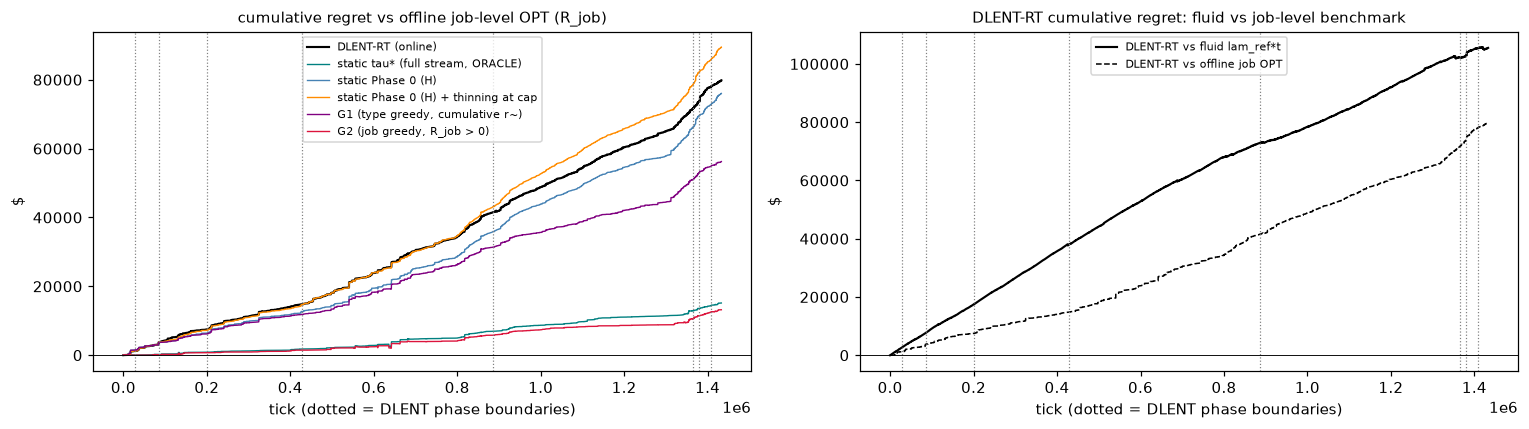

In [20]:
order = np.argsort(S0.tick)
tk = S0.tick[order]
Rr = R0["R_job"][order]
lam_ref = R0["st_ref"].lam_star
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
cum_opt = np.cumsum(Rr * R0["opt"]["x"][order])
for (name, d), cc in zip(ALGS0.items(), ["k", "teal", "steelblue", "darkorange", "purple", "crimson"]):
    if name.startswith("offline"):
        continue
    cum = np.cumsum(Rr * d["admit"][order])
    ax[0].plot(tk, cum_opt - cum, color=cc, lw=1.4 if name.startswith("DLENT") else 0.9, label=name)
    if name.startswith("DLENT"):
        ax[1].plot(tk, lam_ref * tk - cum, color="k", lw=1.4, label="DLENT-RT vs fluid lam_ref*t")
        ax[1].plot(tk, cum_opt - cum, color="k", ls="--", lw=1.0, label="DLENT-RT vs offline job OPT")
for a_ in ax:
    for b in PH0["tau_start"].iloc[1:]:
        a_.axvline(b, color="gray", ls=":", lw=0.8)
    a_.axhline(0, color="k", lw=0.6); a_.set_xlabel("tick (dotted = DLENT phase boundaries)"); a_.set_ylabel("$")
    a_.legend(fontsize=7)
ax[0].set_title("cumulative regret vs offline job-level OPT (R_job)", fontsize=10)
ax[1].set_title("DLENT-RT cumulative regret: fluid vs job-level benchmark", fontsize=10)
plt.tight_layout(); plt.show()

In [21]:
def per_phase_regret(run, algs):
    a, ph = run["A"], run["ph"]
    R_job, x = run["R_job"], run["opt"]["x"]
    rows = []
    for _, p in ph.iterrows():
        m = int(p["m"]); ii = a.loc[a["m"] == m, "i"].to_numpy()
        opt_m = float(R_job[ii][x[ii]].sum())
        row = {"phase": m, "R_OPT job (phase) $": opt_m,
               "DLENT fluid regret (code: bench_hindsight - R) $": float(p["regret_hindsight"])}
        for name, d in algs.items():
            if name.startswith("offline"):
                continue
            row[f"regret {name} $"] = regret(float(R_job[ii][d["admit"][ii]].sum()), opt_m)
        rows.append(row)
    df = pd.DataFrame(rows).set_index("phase")
    df.loc["total"] = df.sum()
    return df

PR0 = per_phase_regret(R0, ALGS0)
display(PR0.style.format(precision=3))

,R_OPT job (phase) $,DLENT fluid regret (code: bench_hindsight - R) $,regret DLENT-RT (online) $,"regret static tau* (full stream, ORACLE) $",regret static Phase 0 (H) $,regret static Phase 0 (H) + thinning at cap $,"regret G1 (type greedy, cumulative r~) $","regret G2 (job greedy, R_job > 0) $"
phase,,,,,,,,
1,1467.113,1238.290,1212.954,52.502,1489.232,1212.334,1488.766,0.644
2,3363.681,3518.172,2554.042,188.808,2245.618,2612.508,2226.841,150.604
3,5669.750,4914.745,3738.764,640.742,2688.181,3441.445,2458.026,583.982
4,10117.220,10191.253,7283.405,917.620,6266.044,7421.112,5644.117,721.846
5,38641.557,36423.536,26773.106,5169.792,23247.269,28472.904,19572.789,4334.780
6,49685.822,39239.624,30118.246,5932.454,30345.213,35564.237,19647.756,4774.208
7,2949.432,2733.167,2185.268,680.638,3249.737,3514.927,2074.858,907.665
8,4766.451,4955.691,4266.301,956.142,3461.706,3815.517,1886.608,1153.813
9,4080.990,2925.318,1717.792,616.229,3032.079,3401.086,1238.820,563.020


## Section 6: capacity_scale sweep

Same seeds, same stream, same BASE config; only c is multiplied before Phase 0. ξ_used is the forced
`constants.xi_override`; ξ_data, the thinning cap and the gate change with the scale (Section 0.1).

In [22]:
sweep = []
for s, run in RUNS.items():
    sm, ep, c = run["res"].summary, run["model"].ep, run["model"].c
    a = run["A"]
    bt, _, bd = baseline_table(run)
    mean, peak = occ_stats(run["te"], run["Ue"], 1, int(run["model"].ds.T))
    sweep.append({
        "capacity_scale": s, "c_cpu": c[0], "c_ram": c[1], "xi_data": run["ds"].xi, "xi_used": ep.xi,
        "p_U cap": run["p_cap"], "p_U min": a["p_U"].min(), "p_U mean": a["p_U"].mean(),
        "phys gate: jobs A>c": int(np.any(run["model"].stream.A > c, axis=1).sum()),
        "phases": sm["n_phases"], "end reasons": ", ".join(f"{k}:{v}" for k, v in sm["phase_end_reasons"].items() if v),
        "admitted": sm["n_admitted"], "adm rate %": 100 * sm["n_admitted"] / sm["n_arrivals"],
        "rej oracle": int((a["decision"] == "oracle reject").sum()),
        "rej thinning": int((a["decision"] == "thinning reject").sum()),
        "rej physical": int((a["decision"] == "physical reject").sum()),
        "occ cpu mean %": 100 * mean[0] / c[0], "occ ram mean %": 100 * mean[1] / c[1],
        "occ cpu peak %": 100 * peak[0] / c[0], "occ ram peak %": 100 * peak[1] / c[1],
        "R_ALG $": sm["R_total"],
        "R_OPT fluid $": bd["R_OPT fluid (bench_global)"], "R_OPT job $": bd["R_OPT job MILP"],
        "R_ALG/R_OPT fluid": bt.loc["DLENT-RT (online)", "R / R_OPT fluid"],
        "R_ALG/R_OPT job": bt.loc["DLENT-RT (online)", "R / R_OPT job"],
        "R_ALG/R_static tau*": bt.loc["static tau* (full stream, ORACLE)", "R_ALG / R"],
        "R_ALG/R_static P0": bt.loc["static Phase 0 (H)", "R_ALG / R"],
        "regret vs job OPT $": bt.loc["DLENT-RT (online)", "regret vs job OPT $"],
        "regret vs fluid $": bt.loc["DLENT-RT (online)", "regret vs fluid $"],
        "adm R_job<0 % (ALG)": bt.loc["DLENT-RT (online)", "adm with R_job<0 %"],
        "tau* (hindsight)": np.round(run["st_ref"].tau, 6),
    })
SWEEP = pd.DataFrame(sweep).set_index("capacity_scale")
display(SWEEP.T.style.format(precision=4))

capacity_scale,0.500000,1.000000
c_cpu,0.2007,0.4014
c_ram,0.1308,0.2616
xi_data,9.8286,4.9143
xi_used,0.0010,0.0010
p_U cap,0.6650,0.6650
p_U min,0.1085,0.1865
p_U mean,0.6381,0.6543
phys gate: jobs A>c,2650,1680
phases,12,9
end reasons,"test1:5, timeout:6, horizon:1","test1:1, test2:1, timeout:6, horizon:1"


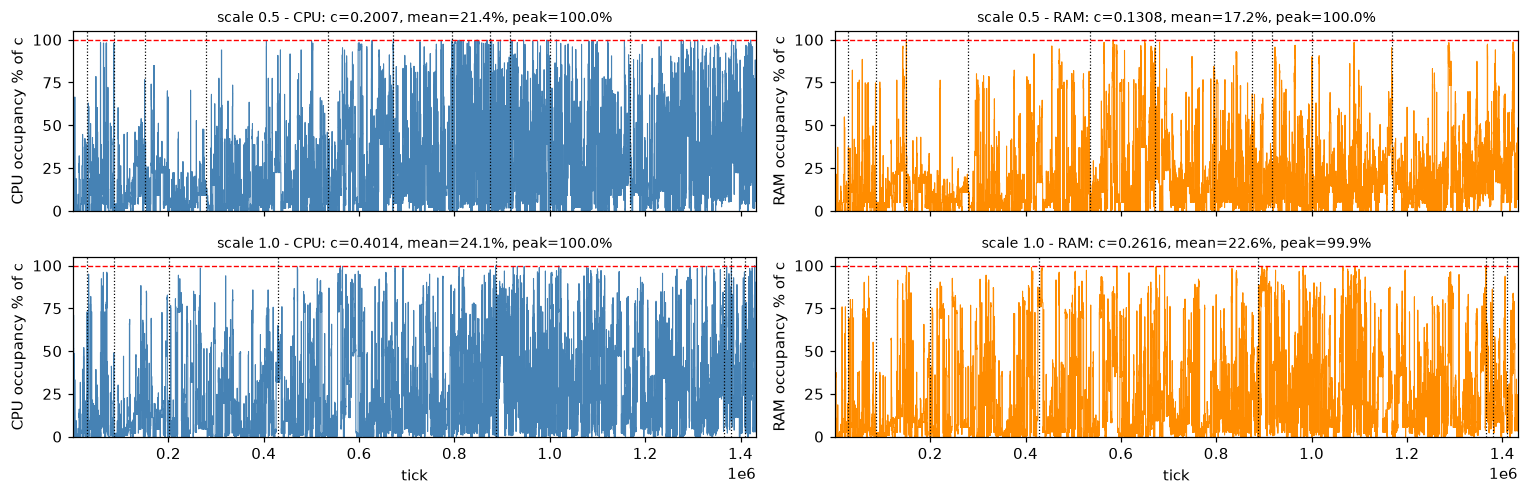

In [23]:
fig, axes = plt.subplots(len(RUNS), 2, figsize=(14, 2.3 * len(RUNS)), sharex=True, squeeze=False)
for (s, run), (a1, a2) in zip(RUNS.items(), axes):
    plot_occupancy(a1, a2, run, title=f"scale {s} - ")
for a_ in axes[-1]:
    a_.set_xlabel("tick")
plt.tight_layout(); plt.show()

## Section 7: Anomalies (numbers only)

In [24]:
an = []
# 1. |H| and s_C depend on data.n0 (this notebook and default.yaml: n0 = 10,000)
for n0 in sorted({10_000, BASE.data.n0}):
    c_n = apply_overrides(BASE, {"data.n0": n0})
    ds_n = load_dataset(c_n); st_n = run_phase0(ds_n, c_n)
    an.append({"item": f"s_C with data.n0={n0:,}", "value": f"{st_n.carbon_price:.3f} $/kgCO2 "
               f"(|H|={ds_n.H.n:,}, |stream|={ds_n.stream.n:,}, K_q={st_n.norm_info['K_q']:.4g}, "
               f"D_q={st_n.norm_info['D_q']:.4g})"})
# 2. negative payments (payment = phi_tilde of the type's bin floor; lognormal: phi(L) can be < 0)
adm = A0[A0["admit"]]
negp = adm[adm["payment"] < 0]
an.append({"item": "admitted jobs with payment < 0",
           "value": f"{len(negp):,} / {len(adm):,} ({100 * len(negp) / max(len(adm), 1):.1f}%), sum = "
                    f"{negp['payment'].sum():,.2f} $; per phase {negp.groupby('m').size().to_dict()}; "
                    f"bins k {sorted(negp['k_bin'].unique().tolist())[:12]}{'...' if negp['k_bin'].nunique() > 12 else ''}"})
an.append({"item": "admitted jobs with payment > bid v", "value": f"{int((adm['payment'] > adm['v']).sum()):,}"})
for m, st in enumerate(M0.states, start=1):
    pp = st.p > 0
    an.append({"item": f"phase {m} state: populated types with phi_tilde < 0",
               "value": f"{int((st.phi_tilde[pp] < 0).sum())} / {int(pp.sum())} "
                        f"(p-mass {100 * st.p[pp][st.phi_tilde[pp] < 0].sum() / st.p[pp].sum():.1f}%)"})
# 3. jobs bigger than the cluster
big = np.any(S0.A > M0.c, axis=1)
an.append({"item": "xi_data = max a_max/c (scale 1)", "value": f"{R0['ds'].xi:.4f}  (forced xi_used = {M0.ep.xi})"})
an.append({"item": "stream jobs with A_i > c_i (never admissible)", "value": f"{int(big.sum()):,} ({100 * big.mean():.2f}%)"})
# 4. shadow prices and fluid LP load (only r~ > 0 types can enter the LP-RS optimum)
for m, st in enumerate(M0.states + [R0["st_ref"]], start=1):
    pos = st.r_tilde > 0
    load = (st.p[pos, None] * st.v[pos]).sum(0) / M0.c
    name = f"phase {m} state" if m <= len(M0.states) else "reference (full stream)"
    an.append({"item": f"{name}: tau, fluid load sum_(r~>0) p_j v_j / c",
               "value": f"tau={np.round(st.tau, 6)}, load={np.round(load, 4)}"})
pr = R0["st_ref"].p > 0
an.append({"item": "reference types: populated / stream jobs",
           "value": f"{int(pr.sum()):,} / {S0.n:,} ({S0.n / pr.sum():.2f} jobs per populated type)"})
# 5. tests and gamma
mx = max(abs(st.r_tilde[st.p > 0]).max() for st in M0.states)
an.append({"item": "max |r~| over populated types (all phase states)", "value": f"{mx:.3f} $ vs gamma_used = {M0.ep.gamma}"})
an.append({"item": "phase end reasons", "value": str(R0["res"].summary["phase_end_reasons"])})
an.append({"item": "max over phases of (Test2 lhs - thr)", "value": f"{ACC0['max(Test2 lhs - thr)'].max():.4g}"})
an.append({"item": "min over phases of Test3 screen margin", "value": f"{ACC0['min Test3 screen margin'].min():.4g}"})
# 6. reward bases
an.append({"item": "R_ALG logged (summary R_total) vs re-scored with R_job",
           "value": f"{R0['res'].summary['R_total']:,.2f} vs {BT0.loc['DLENT-RT (online)', 'R $']:,.2f} $ (asserted equal)"})
an.append({"item": "R_OPT fluid vs offline job-level MILP",
           "value": f"{BOUNDS0['R_OPT fluid (bench_global)']:,.2f} vs {BOUNDS0['R_OPT job MILP']:,.2f} $"})
with pd.option_context("display.max_colwidth", None):
    display(pd.DataFrame(an).set_index("item"))

,value
item,
"s_C with data.n0=10,000","228.184 $/kgCO2 (|H|=10,000, |stream|=15,308, K_q=0.06984, D_q=15.94)"
admitted jobs with payment < 0,"1,091 / 6,657 (16.4%), sum = -8,926.09 $; per phase {1: 8, 2: 13, 3: 27, 4: 97, 5: 374, 6: 483, 7: 25, 8: 38, 9: 26}; bins k [6, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]..."
admitted jobs with payment > bid v,0
phase 1 state: populated types with phi_tilde < 0,0 / 2673 (p-mass 0.0%)
phase 2 state: populated types with phi_tilde < 0,0 / 139 (p-mass 0.0%)
phase 3 state: populated types with phi_tilde < 0,0 / 350 (p-mass 0.0%)
phase 4 state: populated types with phi_tilde < 0,0 / 543 (p-mass 0.0%)
phase 5 state: populated types with phi_tilde < 0,0 / 934 (p-mass 0.0%)
phase 6 state: populated types with phi_tilde < 0,0 / 1773 (p-mass 0.0%)


## Export (week-29 report)

Writes figures (PNG, dpi 200) to `reports/week30/figures/` and tables (CSV) to `reports/week30/tables/`.
Figures are re-rendered by re-running the plotting cells above on the results already in memory, with
`plt.show` redirected to `savefig` (nothing is recomputed). Tables are the DataFrames built above; Tables 3, 7 and
the admitted-R<0 summary are arithmetic on those results.

In [25]:
import io, contextlib
REPORT_DIR = ROOT / "reports" / "week30" / (f"{REGIME_TAG}_nb" if REGIME else "")   # a named regime writes apart
FIG_DIR, TAB_DIR = REPORT_DIR / "figures", REPORT_DIR / "tables"
FIG_DIR.mkdir(parents=True, exist_ok=True)
TAB_DIR.mkdir(parents=True, exist_ok=True)

sys.path.insert(0, str(ROOT / "notebooks" / "src"))
from build import parse as _parse_src
_SRC = [c.source for c in _parse_src((ROOT / "notebooks" / "src" / "03_main_algorithm_analysis.py").read_text())
        if c.cell_type == "code"]

# (file stem, unique marker of the plotting cell, names for successive plt.show calls or None = numbered)
FIG_SPECS = [
    ("fig01_bids_phi", 'qhist(ax[0], A0["v"]', ["fig01_bids_phi"]),
    ("fig02_objectives_job_type", 'qhist(ax[0, 0], A0["CV"]', ["fig02_objectives_job_type"]),
    ("fig03_margin_phase", "N_PLOT = 800", None),
    ("fig04_occupancy", "plot_occupancy(ax[0], ax[1], R0", ["fig04_occupancy"]),
    ("fig05_phase_bars", "body = PT0.drop", ["fig05_phase_bars"]),
    ("fig06_accuracy", "METRICS = [", ["fig06_accuracy", "fig06b_theory_radii"]),
    ("fig07_cumulative_regret", "cum_opt = np.cumsum", ["fig07_cumulative_regret"]),
    ("fig08_occupancy_sweep", "zip(RUNS.items(), axes)", ["fig08_occupancy_sweep"]),
]
_real_show, _real_display = plt.show, display
saved_figs = []
for base, marker, names in FIG_SPECS:
    src = next(s for s in _SRC if marker in s and "FIG_SPECS" not in s)
    count = [0]
    def _save_show(*_a, _base=base, _names=names, _count=count, **_k):
        _count[0] += 1
        name = _names[_count[0] - 1] if _names else f"{_base}{_count[0]}"
        fig = plt.gcf()
        fig.savefig(FIG_DIR / f"{name}.png", dpi=200, bbox_inches="tight")
        plt.close(fig)
        saved_figs.append(name)
    plt.show = _save_show
    globals()["display"] = lambda *_a, **_k: None
    try:
        with contextlib.redirect_stdout(io.StringIO()):
            exec(src, globals())
    finally:
        plt.show = _real_show
        globals()["display"] = _real_display
plt.close("all")

def _csv(df, name, **kw):
    df.to_csv(TAB_DIR / f"{name}.csv", **kw)
    return name

ep0, sm0 = M0.ep, R0["res"].summary
setup = pd.Series({
    "trace": Path(BASE.data.batch_csv).name, "grid data": Path(BASE.data.grid_csv).name,
    "data.n0 (notebook override)": BASE.data.n0,
    "seed run (Phase-0 bids)": BASE.run.seed, "seed stream bids": BASE.run.seed + BASE.online.bid_seed_offset,
    "seed thinning": BASE.run.seed + BASE.online.thinning_seed_offset,
    "|H|": ds0.H.n, "|stream|": ds0.stream.n, "T (ticks)": ds0.T, "tick seconds": BASE.time.tick_seconds,
    "d_max (ticks)": ds0.d_max_steps, "c_cpu": ds0.capacity[0], "c_ram": ds0.capacity[1],
    "capacity mode": BASE.capacity.mode, "capacity fraction": BASE.capacity.fraction,
    "capacity concurrency_quantile": BASE.capacity.concurrency_quantile,
    "a_max_cpu": ds0.a_max[0], "a_max_ram": ds0.a_max[1], "xi_data": ds0.xi, "xi_used": ep0.xi,
    "gamma_used": ep0.gamma, "gamma_data": ep0.gamma_data, "delta": ep0.delta, "eps_D": ep0.eps_D,
    "thinning cap (1-xi)/(1+eps_D)": R0["p_cap"], "p_U min": A0["p_U"].min(), "p_U max": A0["p_U"].max(),
    "lambda1": L1, "lambda2": L2, "lambda3": L3, "lambda sum": L1 + L2 + L3,
    "s_C ($/kgCO2, frozen)": SC0, "normalization": "quantile_linear",
    "quantile q": BASE.normalization.quantile,
    "bid model": "lognormal", "bid sigma": BASE.bid.sigma, "u0": BASE.bid.base_utility_u0,
    "k_star": BASE.grid.k_star, "hw profiles": BASE.hardware.n_profiles, "model": BASE.model.kind,
    "n_type_min": BASE.phase_transition.n_type_min, "n_min": BASE.phase_transition.n_min,
}, name="value")

t3 = pd.DataFrame([{"phase": m, "tau_cpu": st.tau[0], "tau_ram": st.tau[1],
                    "arrivals": int((A0["m"] == m).sum()),
                    "points plotted": int(min(N_PLOT, (A0["m"] == m).sum())),
                    "subsampled": bool((A0["m"] == m).sum() > N_PLOT)}
                   for m, st in enumerate(M0.states, start=1)]).set_index("phase")

_neg = A0[A0["R_job"] < 0]
_na = _neg[_neg["admit"]]
adm_neg = pd.Series({
    "arrivals": len(A0), "R_job<0": len(_neg), "R_job<0 %": 100 * len(_neg) / len(A0),
    "R_nocarb<0 %": 100 * (A0["R_nocarb"] < 0).mean(),
    "admitted": int(A0["admit"].sum()), "admitted with R_job<0": len(_na),
    "admitted R_job<0 % of admitted": 100 * len(_na) / A0["admit"].sum(),
    "admitted R_job<0 % of negative jobs": 100 * len(_na) / max(len(_neg), 1),
    "of admitted R_job<0: score>0 %": 100 * (_na["score"] > 0).mean(),
    "of admitted R_job<0: Pi_job<0 %": 100 * (_na["PI"] < 0).mean(),
    "of admitted R_job<0: phi_mech<0 %": 100 * (_na["phi_mech"] < 0).mean(),
    "of admitted R_job<0: R_nocarb>=0 % (carbon flips sign)": 100 * (_na["R_nocarb"] >= 0).mean(),
    "of admitted R_job<0: mean r~_type $": _na["r_tilde"].mean(),
    "of admitted R_job<0: mean R_job $": _na["R_job"].mean(),
    "admitted with payment<0": int((A0.loc[A0["admit"], "payment"] < 0).sum()),
}, name="value")

# Discretization loss = job OPT - fluid OPT (per-job decisions vs the fluid LP on type means).
# The rest, fluid OPT - online, mixes estimation, thinning and learning; it is NOT split yet
# (preliminary). The static baselines of table06 are reference policies, not a decomposition.
_opt, _fluid = BOUNDS0["R_OPT job MILP"], BOUNDS0["R_OPT fluid (bench_global)"]
_alg = BT0["R $"]["DLENT-RT (online)"]
_tot = _opt - _alg
t7 = pd.DataFrame([
    {"step": "job OPT -> fluid OPT", "attributed to": "discretization loss", "$": _opt - _fluid},
    {"step": "fluid OPT -> DLENT-RT online", "attributed to": "estimation + thinning + learning (not yet separated; preliminary)", "$": _fluid - _alg},
    {"step": "total regret (job OPT - online)", "attributed to": "", "$": _tot},
]).set_index("step")
t7["% of total"] = 100 * t7["$"] / _tot
t7b = PR0.drop(index="total").copy()
t7b.insert(0, "arrivals", A0.groupby("m").size())
t7b["DLENT regret per arrival $"] = t7b["regret DLENT-RT (online) $"] / t7b["arrivals"]
t7b.loc["total"] = t7b.sum()
t7b.loc["total", "DLENT regret per arrival $"] = t7b.loc["total", "regret DLENT-RT (online) $"] / t7b.loc["total", "arrivals"]

t8 = SWEEP[["c_cpu", "c_ram", "xi_data", "phys gate: jobs A>c", "p_U min", "phases", "end reasons", "admitted",
            "adm rate %", "rej physical", "rej thinning", "occ cpu mean %", "occ ram mean %", "occ cpu peak %",
            "occ ram peak %", "R_ALG $", "R_OPT job $", "R_ALG/R_OPT job",
            "R_OPT fluid $", "R_ALG/R_OPT fluid", "tau* (hindsight)"]].copy()
t8["tau* (hindsight)"] = t8["tau* (hindsight)"].astype(str)

saved_tabs = [
    _csv(setup.to_frame(), "table00_setup"),
    _csv(const_df.T, "table00b_constants_per_scale"),
    _csv(pd.DataFrame(desc).set_index(["level", "objective"]), "table01_objective_quantiles"),
    _csv(pd.DataFrame(neg_rows).set_index(["level", "scope"]), "table02_negative_reward"),
    _csv(t3, "table03_phase_tau_points"),
    _csv(PT0, "table04_phase_results"),
    _csv(adm_neg.to_frame(), "table04b_admitted_negative"),
    _csv(ACC0, "table05_accuracy"),
    _csv(V0, "table05b_monotonicity"),
    _csv(BT0, "table06_baselines"),
    _csv(pd.Series(BOUNDS0, name="$").to_frame(), "table06b_benchmarks"),
    _csv(t7, "table07_regret_decomposition"),
    _csv(t7b, "table07b_regret_per_phase"),
    _csv(t8, "table08_capacity_sweep"),
    _csv(pd.DataFrame(an).set_index("item"), "table10_anomalies"),
]
print(f"figures -> {FIG_DIR}:")
print("  " + "\n  ".join(saved_figs))
print(f"tables -> {TAB_DIR}:")
print("  " + "\n  ".join(saved_tabs))

figures -> /Users/francescodangolo/Projects/dlent_rt/reports/week30/small_cluster_nb/figures:
  fig01_bids_phi
  fig02_objectives_job_type
  fig03_margin_phase1
  fig03_margin_phase2
  fig03_margin_phase3
  fig03_margin_phase4
  fig03_margin_phase5
  fig03_margin_phase6
  fig03_margin_phase7
  fig03_margin_phase8
  fig03_margin_phase9
  fig04_occupancy
  fig05_phase_bars
  fig06_accuracy
  fig06b_theory_radii
  fig07_cumulative_regret
  fig08_occupancy_sweep
tables -> /Users/francescodangolo/Projects/dlent_rt/reports/week30/small_cluster_nb/tables:
  table00_setup
  table00b_constants_per_scale
  table01_objective_quantiles
  table02_negative_reward
  table03_phase_tau_points
  table04_phase_results
  table04b_admitted_negative
  table05_accuracy
  table05b_monotonicity
  table06_baselines
  table06b_benchmarks
  table07_regret_decomposition
  table07b_regret_per_phase
  table08_capacity_sweep
  table10_anomalies


## Section 8: capacity × type-grid sweep (week 30)

Six configurations, each an override of `BASE` (configs/default.yaml with the notebook's σ = 0.3 and n0 = 10,000;
seed 42; no yaml file added):
* **capacity**: `fraction_of_concurrency_quantile` with `concurrency_quantile` = 0.7 and fraction ∈ {0.3, 0.5, 1.0},
  c_i = fraction × (0.7 time-weighted quantile of the concurrent occupancy of H + stream). The mode literally named
  `fraction_of_peak` exists too, but it sizes on the MAX concurrency and takes no quantile, so it is not used here.
* **`capacity.drop_jobs_exceeding_capacity` = true**: after the outlier policy (0.90 / 0.95, unchanged) and the
  sizing, every job with A_ij > c_i on any resource leaves H and the stream, for every model and benchmark. The
  "would drop" columns are computed with the flag OFF on the same c: jobs removed, their share of the stream's
  Σ R_job⁺, and their share of Phase 0's profitable load (H jobs of types with r̃ > 0, volume A_type·D / H span).
* **type grid**: default (k* = 128, 32 hardware profiles) and reduced (k* = 64, 16 profiles); 5 priority classes.

For each configuration, on the same stream, R_job and physical gate: DLENT-RT online, StaticPolicy (Phase 0),
G1 (`TypeGreedyPolicy` as implemented: cumulative running mean of R_job over ALL arrivals, i.e. it uses the
realised R_job of rejected jobs; a strict observable-only G1 is not implemented), G2 (`JobGreedyPolicy`), the
fluid OPT and the job-level OPT (MILP, time limit below; gap reported). Decision errors = share of arrivals with
sign(R_job) ≠ sign(r̃ of their type): Phase 0 types (stream arrivals of types populated in H), G1 (r̃ used at the
decision, observed types) and DLENT-RT (r̃ of the phase state at the arrival).

**The two grids do not run on an identical cluster or stream.** Each job's request A is snapped to its hardware
profile (k-means centroid), so `hardware.n_profiles` changes A, hence the occupancy series that sizes c, the drop
filter, the physical gate, the job energy (C_elec, K) and R_job; R_job also depends on the grid through s_C (Phase 0
quantiles). c and s_C are reported per run.

The six configurations run in parallel worker processes (`notebooks/src/capacity_grid_sweep.run_one`).

In [26]:
import multiprocessing as mp
from concurrent.futures import ProcessPoolExecutor
sys.path.insert(0, str(ROOT / "notebooks" / "src"))
from capacity_grid_sweep import run_one

SWEEP_Q = 0.7
SWEEP_FRACTIONS = (0.3, 0.5, 1.0)
SWEEP_GRIDS = {"default (k*=128, hw=32)": (128, 32), "reduced (k*=64, hw=16)": (64, 16)}
MILP_TIME_LIMIT = 600.0
sweep_cfgs = {
    (f, g): apply_overrides(BASE, {"capacity.mode": "fraction_of_concurrency_quantile",
                                   "capacity.concurrency_quantile": SWEEP_Q, "capacity.fraction": f,
                                   "capacity.drop_jobs_exceeding_capacity": True,
                                   "grid.k_star": k, "hardware.n_profiles": h}).validate()
    for f in SWEEP_FRACTIONS for g, (k, h) in SWEEP_GRIDS.items()
}
t_sw = time.time()
with ProcessPoolExecutor(max_workers=min(4, len(sweep_cfgs)), mp_context=mp.get_context("spawn")) as pool:  # ~1 GB each
    futs = {key: pool.submit(run_one, c, f"fraction={key[0]} {key[1]}", MILP_TIME_LIMIT)
            for key, c in sweep_cfgs.items()}
    SW = {key: fu.result() for key, fu in futs.items()}
for key, o in SW.items():
    print(f"fraction={key[0]:<4} {key[1]:<24} online {o['t_online_s']:.0f} s, MILP {o['t_milp_s']:.0f} s "
          f"({o['milp_status']}, gap {o['milp_gap']:.2e})")
print(f"sweep wall time {time.time() - t_sw:.0f} s")

fraction=0.3  default (k*=128, hw=32)  online 300 s, MILP 1 s (Optimization terminated successfully. (HiGHS Status 7: Optimal), gap 4.42e-05)
fraction=0.3  reduced (k*=64, hw=16)   online 158 s, MILP 1 s (Optimization terminated successfully. (HiGHS Status 7: Optimal), gap 2.88e-05)
fraction=0.5  default (k*=128, hw=32)  online 323 s, MILP 1 s (Optimization terminated successfully. (HiGHS Status 7: Optimal), gap 2.66e-05)
fraction=0.5  reduced (k*=64, hw=16)   online 232 s, MILP 1 s (Optimization terminated successfully. (HiGHS Status 7: Optimal), gap 5.40e-08)
fraction=1.0  default (k*=128, hw=32)  online 263 s, MILP 0 s (Optimization terminated successfully. (HiGHS Status 7: Optimal), gap 1.93e-05)
fraction=1.0  reduced (k*=64, hw=16)   online 165 s, MILP 0 s (Optimization terminated successfully. (HiGHS Status 7: Optimal), gap 1.66e-05)
sweep wall time 427 s


In [27]:
SW_DF = pd.DataFrame([{"fraction": k[0], "grid": k[1], **v} for k, v in SW.items()]).set_index(["fraction", "grid"])
POLS = [("DLENT", "DLENT-RT"), ("static", "StaticPolicy (P0)"), ("G1", "G1"), ("G2", "G2")]
cols = {
    # cluster and capacity filter
    "c_cores": "c CPU (cores)", "c_GB": "c RAM (GB)",
    "drop_n_H": "would drop: H jobs", "drop_n_stream": "would drop: stream jobs",
    "drop_share_Rpos_pct": "would drop: % of stream ΣR_job⁺",
    "drop_share_prof_load_cpu_pct": "would drop: % of P0 profitable load CPU",
    "drop_share_prof_load_ram_pct": "would drop: % of P0 profitable load RAM",
    "n_H": "H jobs kept", "n_stream": "stream jobs kept",
    # Phase 0
    "p0_lp_use_cpu_pct": "P0 LP usage CPU %", "p0_lp_use_ram_pct": "P0 LP usage RAM %",
    "p0_prof_load_cpu_pct": "P0 profitable load CPU %", "p0_prof_load_ram_pct": "P0 profitable load RAM %",
    "tau0_cpu": "tau_0 CPU", "tau0_ram": "tau_0 RAM", "n_types": "types", "n_types_populated": "populated types",
    "jobs_per_populated_type": "H jobs per populated type", "s_C": "s_C $/kgCO2",
    # online DLENT-RT
    "n_phases": "phases", **{f"end_{r}": f"end {r}" for r in ("timeout", "test1", "test2", "test3", "horizon")},
    "phases_tau_pos": "phases with tau>0", "tau_per_phase": "tau per phase (cpu,ram)",
    "dlent_phys_rejects": "DLENT physical rejects", "dlent_thinning_rejects": "DLENT thinning rejects",
    # benchmarks
    "R_fluid": "R fluid OPT $", "R_job_opt": "R job OPT (MILP) $", "milp_gap": "MILP gap",
    **{f"R_{k}": f"R {n} $" for k, n in POLS},
    **{f"pct_fluid_{k}": f"{n} % of fluid" for k, n in POLS},
    **{f"regret_fluid_{k}": f"{n} regret vs fluid $" for k, n in POLS},
    **{f"regret_jobopt_{k}": f"{n} regret vs job OPT $" for k, n in POLS},
    "phys_G1": "G1 physical rejects", "G1_rej_r": "G1 rej r~<=0", "G1_rej_unseen": "G1 rej unseen type",
    "phys_G2": "G2 physical rejects",
    # discretization
    "disc_loss": "discretization loss (job OPT - fluid) $",
    "dec_err_P0_pct": "decision errors P0 types %", "dec_err_G1_pct": "decision errors G1 %",
    "dec_err_DLENT_pct": "decision errors DLENT %",
}
SW_TAB = SW_DF[list(cols)].rename(columns=cols)
for _k, _n in POLS:                                       # R as % of the job OPT of the same configuration
    SW_TAB[f"{_n} % of job OPT"] = 100 * SW_TAB[f"R {_n} $"] / SW_TAB["R job OPT (MILP) $"]
for f in SWEEP_FRACTIONS:
    print(f"\n=== capacity fraction {f} (q = {SWEEP_Q}), rows = grid")
    display(SW_TAB.loc[f].T)

SUMMARY_COLS = ["c CPU (cores)", "c RAM (GB)", "would drop: stream jobs", "tau_0 CPU", "tau_0 RAM", "phases",
                "end timeout", "end test1", "end test2", "end test3", "end horizon", "phases with tau>0",
                "R DLENT-RT $", "R StaticPolicy (P0) $", "R G1 $", "R G2 $", "R fluid OPT $", "R job OPT (MILP) $",
                "DLENT-RT % of fluid", "StaticPolicy (P0) % of fluid", "G1 % of fluid", "G2 % of fluid",
                "DLENT-RT % of job OPT", "StaticPolicy (P0) % of job OPT", "G1 % of job OPT", "G2 % of job OPT",
                "discretization loss (job OPT - fluid) $", "decision errors P0 types %", "decision errors G1 %",
                "H jobs per populated type", "MILP gap"]
SW_SUM = SW_TAB[SUMMARY_COLS]
display(SW_SUM)


=== capacity fraction 0.3 (q = 0.7), rows = grid


grid,"default (k*=128, hw=32)","reduced (k*=64, hw=16)"
c CPU (cores),51.382239,51.051077
c RAM (GB),133.949865,130.689456
would drop: H jobs,1423,1491
would drop: stream jobs,977,1008
would drop: % of stream ΣR_job⁺,3.854596,4.937877
would drop: % of P0 profitable load CPU,29.591566,33.384109
would drop: % of P0 profitable load RAM,22.699493,28.974747
H jobs kept,8577,8509
stream jobs kept,14331,14300
P0 LP usage CPU %,26.19533,28.377432



=== capacity fraction 0.5 (q = 0.7), rows = grid


grid,"default (k*=128, hw=32)","reduced (k*=64, hw=16)"
c CPU (cores),85.637065,85.085129
c RAM (GB),223.249775,217.81576
would drop: H jobs,731,622
would drop: stream jobs,523,447
would drop: % of stream ΣR_job⁺,0.850558,0.145174
would drop: % of P0 profitable load CPU,15.71998,8.345164
would drop: % of P0 profitable load RAM,9.004414,8.286641
H jobs kept,9269,9378
stream jobs kept,14785,14861
P0 LP usage CPU %,21.763961,27.55733



=== capacity fraction 1.0 (q = 0.7), rows = grid


grid,"default (k*=128, hw=32)","reduced (k*=64, hw=16)"
c CPU (cores),171.274131,170.170257
c RAM (GB),446.499551,435.631519
would drop: H jobs,0,0
would drop: stream jobs,0,0
would drop: % of stream ΣR_job⁺,0.0,0.0
would drop: % of P0 profitable load CPU,0.0,0.0
would drop: % of P0 profitable load RAM,0.0,0.0
H jobs kept,10000,10000
stream jobs kept,15308,15308
P0 LP usage CPU %,18.486595,21.970763


c CPU (cores)  c RAM (GB)  would drop: stream jobs  tau_0 CPU  tau_0 RAM  phases  end timeout  end test1  end test2  end test3  end horizon  phases with tau>0  R DLENT-RT $  \
fraction grid                                                                                                                                                                                                    
0.3      default (k*=128, hw=32)      51.382239  133.949865                      977        0.0        0.0       6            5          0          0          0            1                  0  40740.415448   
         reduced (k*=64, hw=16)       51.051077  130.689456                     1008        0.0        0.0       8            6          1          0          0            1                  0  52546.161293   
0.5      default (k*=128, hw=32)      85.637065  223.249775                      523        0.0        0.0       6            5          0          0          0            1                  0  41909.920785   
         reduced (k*=64, hw=16)       85.085129  217.815760                      447        0.0        0.0       9            7          1          0          0            1                  0  53342.750234   
1.0      default (k*=128, hw=32)     171.274131  446.499551                        0        0.0        0.0      11            9          0          1          0            1                  0  48242.267411   
         reduced (k*=64, hw=16)      170.170257  435.631519                        0        0.0        0.0      12            9          1          1          0            1                  0  68419.239788   

                                  R StaticPolicy (P0) $         R G1 $         R G2 $  R fluid OPT $  R job OPT (MILP) $  DLENT-RT % of fluid  StaticPolicy (P0) % of fluid  G1 % of fluid  G2 % of fluid  \
fraction grid                                                                                                                                                                                               
0.3      default (k*=128, hw=32)           46525.882093   68840.452949  113505.781311  119169.149903       118745.215907            34.187049                     39.041885      57.767008      95.247622   
         reduced (k*=64, hw=16)            66757.561871   85794.409246  115963.356558  118524.208751       121527.048479            44.333695                     56.323989      72.385557      97.839385   
0.5      default (k*=128, hw=32)           44053.621069   71740.298873  126304.022352  127443.363488       129670.852251            32.885134                     34.567215      56.291906      99.106002   
         reduced (k*=64, hw=16)            71390.210949   97515.466354  130643.174052  130025.902129       134602.098119            41.024711                     54.904607      74.996954     100.474730   
1.0      default (k*=128, hw=32)           54121.640433   82310.769705  153582.175996  149478.419412       154637.328204            32.273734                     36.206993      55.065320     102.745384   
         reduced (k*=64, hw=16)            85655.072980  111975.233243  155002.126944  148855.578716       156438.366292            45.963504                     57.542400      75.224076     104.129202   

                                  DLENT-RT % of job OPT  StaticPolicy (P0) % of job OPT  G1 % of job OPT  G2 % of job OPT  discretization loss (job OPT - fluid) $  decision errors P0 types %  decision errors G1 %  \
fraction grid                                                                                                                                                                                                          
0.3      default (k*=128, hw=32)              34.309100                       39.181269        57.973243        95.587667                              -423.933996                   11.545687             11.596057   
         reduced (k*=64, hw=16)               43.238244         

In [28]:
def _fmt(v):
    if isinstance(v, (int, np.integer)):
        return f"{v:,}"
    if isinstance(v, (float, np.floating)):
        return "nan" if not np.isfinite(v) else (f"{v:,.2f}" if abs(v) >= 1 or v == 0 else f"{v:.3g}")
    return str(v)

def md_table(df, index_name):
    head = "| " + index_name + " | " + " | ".join(map(str, df.columns)) + " |"
    sep = "|" + "---|" * (len(df.columns) + 1)
    body = ["| " + " / ".join(map(str, k if isinstance(k, tuple) else (k,))) + " | "
            + " | ".join(_fmt(v) for v in row) + " |" for k, row in zip(df.index, df.itertuples(index=False))]
    return "\n".join([head, sep, *body])

saved_sw = [_csv(SW_SUM, "table08_capacity_grid_sweep"), _csv(SW_TAB, "table08_capacity_grid_sweep_full")]
md = [f"# Capacity × type-grid sweep: generated tables (nb03 Section 8)\n",
      f"Capacity `fraction_of_concurrency_quantile`, q = {SWEEP_Q}; `drop_jobs_exceeding_capacity` = true; seed "
      f"{BASE.run.seed}; σ = {BASE.bid.sigma}; MILP time limit {MILP_TIME_LIMIT:.0f} s. Generated by the notebook; "
      f"do not edit by hand.\n"]
for f in SWEEP_FRACTIONS:
    saved_sw.append(_csv(SW_TAB.loc[f], f"table08_capacity_grid_sweep_f{f}"))
    md += [f"\n## Fraction {f} (rows = grid)\n", md_table(SW_TAB.loc[f].T, "quantity"), ""]
md += ["\n## Summary across the six runs\n", md_table(SW_SUM.T, "quantity"), ""]
(REPORT_DIR / "capacity_grid_sweep_tables.md").write_text("\n".join(md))
print("tables ->", TAB_DIR, "\n  " + "\n  ".join(saved_sw))
print("markdown ->", REPORT_DIR / "capacity_grid_sweep_tables.md")

tables -> /Users/francescodangolo/Projects/dlent_rt/reports/week30/small_cluster_nb/tables 
  table08_capacity_grid_sweep
  table08_capacity_grid_sweep_full
  table08_capacity_grid_sweep_f0.3
  table08_capacity_grid_sweep_f0.5
  table08_capacity_grid_sweep_f1.0
markdown -> /Users/francescodangolo/Projects/dlent_rt/reports/week30/small_cluster_nb/capacity_grid_sweep_tables.md


## Section 9: Benchmark ladder (the run's config, see the run marker; capacity scale 1.0)

Every row is scored with the same job reward R_job on the same stream (realised $ over the stream). Rows:
* **job-level, no capacity** = Σ R_job⁺; **job-level MILP** = `Benchmarks.job_level_opt` (per-tick capacity, x ∈ {0,1}).
* **bucketed MILP A** = `Benchmarks.job_opt_bucketed(source, "true")`: the same MILP, but the solver sees each job's
  TYPE reward r̃ (its bucket) instead of R_job; true durations in the occupancy (variant A). The row reports the
  REALISED Σ R_job·x of the chosen set. Two bucket sources: **reference** (the full-stream reference state behind the
  fluid OPT: same grid and estimates) and **Phase 0** (the policies' estimate from H; unseen types get r̃ = 0).
* **fluid OPT** = λ̂_ref·T; G2, G1, static Phase 0 (± thinning) and DLENT-RT as in Section 5.
* **feasible ceiling** = Σ R_job⁺ over the stream jobs with A_ij ≤ c_i on every resource: the most ANY policy can
  earn (jobs larger than c never pass the physical gate). Without the drop filter on a small cluster it is below the
  no-capacity bound; otherwise the two coincide.
* **fluid OPT on feasible types only** = the same LP-RS on the reference state with every type whose hardware profile
  A exceeds c on some resource removed (p_j = 0): the fluid benchmark without the load that can never run. Its τ is
  printed below.
* Columns: realised reward, % of the job-level MILP, % of the feasible ceiling.
* **static → static + thinning → DLENT-RT**: cost of thinning = static − static + thinning (same frozen Phase 0 oracle,
  thinned with the online run's random numbers); effect of learning / estimation = DLENT-RT − (static + thinning)
  (ReInit, Tests 1–3, phase-wise thinning).

Decomposition (reports/week30/bucketed_opt.md): discretization cost = job OPT − bucketed OPT, fluid cost =
bucketed OPT − fluid OPT (negative = the fluid OPT is above the bucketed MILP); both with the bucketed MILP's own
objective ("believed", Σ r̃·x) and with its realised value. With the reference buckets and the believed value the two
pieces are exactly "per-job vs bucketed rewards" and "bucketed MILP vs fluid relaxation".

ladder (scale 1.0) in 30 s


,realised $,% of job-level MILP,% of feasible ceiling,gap to row above $
row,,,,
"job-level, no capacity (Σ R_job⁺)","155,579.35",128.85,110.24,nan
feasible ceiling (Σ R_job⁺ over A ≤ c),"141,126.62",116.88,100.00,"14,452.73"
job-level MILP,"120,742.02",100.00,85.56,"20,384.60"
bucketed MILP A (reference buckets),"115,705.84",95.83,81.99,"5,036.17"
bucketed MILP A (Phase 0 buckets),"49,134.15",40.69,34.82,"66,571.69"
fluid OPT,"146,395.19",121.25,103.73,"-97,261.04"
fluid OPT on feasible types only,"135,400.78",112.14,95.94,"10,994.41"
G2 job greedy,"107,551.45",89.08,76.21,"27,849.33"
G1 type greedy,"64,503.43",53.42,45.71,"43,048.02"


fluid OPT on feasible types only: {'fluid feasible-types tau': [0.0, 0.0], 'fluid feasible-types tau is 0': True, 'fluid (all types) tau': [0.0, 0.042513], 'types removed (A > c), populated': 504, 'types populated': 3033, 'stream jobs that fit': 13628, 'stream jobs': 15308}


,$,% of job MILP,change $,attributed to
step,,,,
static Phase 0,44716.94,37.04,nan,nan
static Phase 0 + thinning,31285.95,25.91,-13430.99,cost of thinning (same frozen oracle)
DLENT-RT (theory),40892.14,33.87,9606.19,"learning / estimation (ReInit, tests, phase-wise thinning)"


,status,gap,runtime s,candidates,unseen jobs,unseen types,chosen with R_job<0,peak true occ / c
MILP,,,,,,,,
job-level,Optimization terminated successfully. (HiGHS S...,9.913962e-05,14.105400,NaN,NaN,NaN,NaN,NaN
bucketed A (reference),Optimization terminated successfully. (HiGHS S...,9.924639e-05,28.872037,12621.0,0.0,0.0,439.0,"[0.9999, 0.9999]"
bucketed A (phase0),Optimization terminated successfully. (HiGHS S...,1.862061e-07,0.447491,10227.0,2762.0,1155.0,564.0,"[0.9991, 0.9994]"


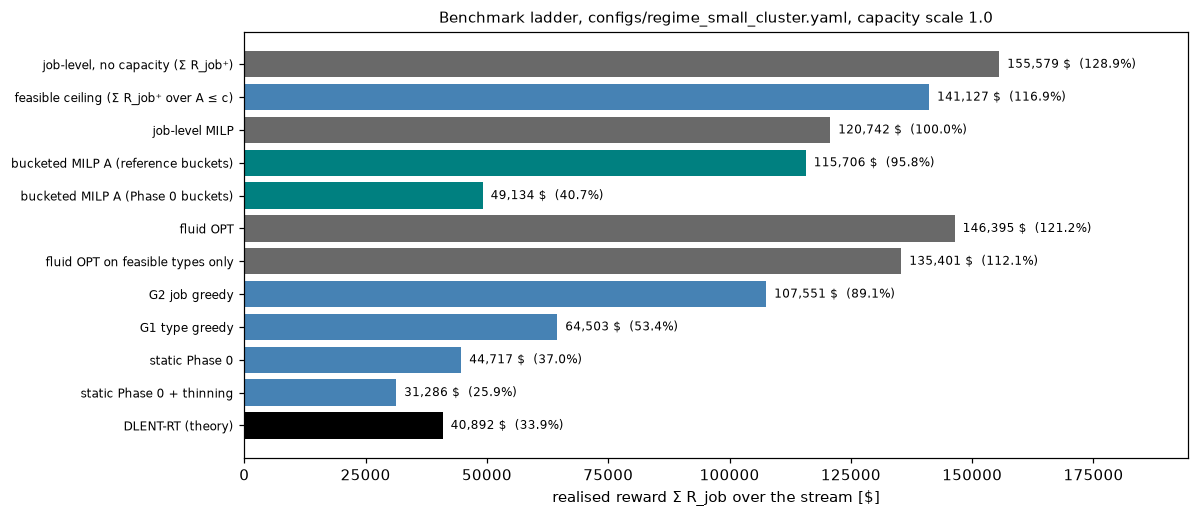

In [29]:
import shutil
FIGS_DIR = ROOT / "reports" / "week30" / f"figs_{REGIME_TAG}" if REGIME else REPORT_DIR / "figs"
FIGS_DIR.mkdir(parents=True, exist_ok=True)
MILP_TL = 600.0


def _savefig(fig, name):
    for d in (FIG_DIR, FIGS_DIR):
        fig.savefig(d / f"{name}.png", dpi=200, bbox_inches="tight")


def ladder_tables(B, opt, admits):
    """Ladder, decomposition and MILP diagnostics from Benchmarks B, its job_level_opt result `opt`, and the
    admitted masks of the policies ({row: mask}). Returns (ladder, decomposition, milps, admitted sets per row)."""
    buck = {src: B.job_opt_bucketed(src, "true", time_limit=MILP_TL) for src in ("reference", "phase0")}
    fluid, job = B.fluid_opt(), opt["R_ip"]
    # feasible ceiling: Σ R_job⁺ over the stream jobs that fit (A_ij <= c_i on every resource)
    fits = ~np.any(B.S.A > B.c[None, :], axis=1)
    ceiling = float(np.maximum(B.R, 0)[fits].sum())
    # fluid OPT on feasible types only: the same LP-RS on the reference state, types whose A exceeds c removed
    ref = B.reference_state
    _, _, A_ref = type_arrays(ref.type_space, ref.grid)
    feas_t = ~np.any(A_ref > B.c[None, :], axis=1)
    lp_feas = solve_lp_rs(p=ref.p * feas_t, r=ref.r_tilde, v=ref.v, c=B.c, presolve=BASE.lp.presolve)
    fluid_feas = float(lp_feas.optimum) * B.T
    rows = [("job-level, no capacity (Σ R_job⁺)", opt["R_nocap"], None),
            ("feasible ceiling (Σ R_job⁺ over A ≤ c)", ceiling, None),
            ("job-level MILP", job, opt["x"]),
            ("bucketed MILP A (reference buckets)", buck["reference"]["R_real"], buck["reference"]["x"]),
            ("bucketed MILP A (Phase 0 buckets)", buck["phase0"]["R_real"], buck["phase0"]["x"]),
            ("fluid OPT", fluid, None),
            ("fluid OPT on feasible types only", fluid_feas, None),
            *[(k, B.score(m), m) for k, m in admits.items()]]
    lad = pd.DataFrame([{"row": r, "realised $": v, "% of job-level MILP": 100 * v / job,
                         "% of feasible ceiling": 100 * v / ceiling} for r, v, _ in rows])
    lad = lad.set_index("row")
    lad["gap to row above $"] = -lad["realised $"].diff()
    info = {"fluid feasible-types tau": np.round(lp_feas.tau, 6).tolist(),
            "fluid feasible-types tau is 0": bool(np.all(lp_feas.tau <= 1e-12)),
            "fluid (all types) tau": np.round(ref.tau, 6).tolist(),
            "types removed (A > c), populated": int((~feas_t & (ref.p > 0)).sum()),
            "types populated": int((ref.p > 0).sum()), "stream jobs that fit": int(fits.sum()),
            "stream jobs": int(fits.size)}
    dec = []
    for src in ("reference", "phase0"):
        for kind, key in (("believed Σ r̃·x", "R_believed"), ("realised Σ R·x", "R_real")):
            v = buck[src][key]
            dec.append({"buckets": src, "bucketed value": kind, "bucketed $": v,
                        "discretization cost (job OPT − bucketed) $": job - v,
                        "fluid cost (bucketed − fluid) $": v - fluid, "sum = job OPT − fluid $": job - fluid})
    dec = pd.DataFrame(dec).set_index(["buckets", "bucketed value"])
    milps = pd.DataFrame([{"MILP": "job-level", "status": opt["status"], "gap": opt["gap"],
                           "runtime s": opt.get("runtime_s", np.nan)},
                          *[{"MILP": f"bucketed A ({s})", "status": o["status"], "gap": o["gap"],
                             "runtime s": o["runtime_s"], "candidates": o["n_candidates"],
                             "unseen jobs": o["n_unseen_jobs"], "unseen types": o["n_unseen_types"],
                             "chosen with R_job<0": o["n_chosen_R_neg"],
                             "peak true occ / c": str(np.round(o["peak_true_occ_over_c"], 4).tolist())}
                            for s, o in buck.items()]]).set_index("MILP")
    for o in buck.values():      # variant A is feasible for the job MILP: realised <= job OPT (within its gap)
        assert o["feasible_true"] and o["R_real"] <= job * (1 + max(opt["gap"], 0)) + 1e-6
    return lad, dec, milps, {r: m for r, _, m in rows if m is not None}, info


def plot_ladder(lad, title, name):
    fig, ax = plt.subplots(figsize=(11, 4.8))
    col = ["dimgray" if r.startswith(("job-level", "fluid")) else "teal" if r.startswith("bucketed")
           else "black" if r.startswith("DLENT") else "steelblue" for r in lad.index]
    y = np.arange(len(lad))[::-1]
    ax.barh(y, lad["realised $"], color=col)
    for yy, v, pc in zip(y, lad["realised $"], lad["% of job-level MILP"]):
        ax.text(v, yy, f"  {v:,.0f} $  ({pc:.1f}%)", va="center", fontsize=8)
    ax.set_yticks(y, lad.index, fontsize=8)
    ax.set_xlabel("realised reward Σ R_job over the stream [$]")
    ax.set_xlim(0, lad["realised $"].max() * 1.25)
    ax.set_title(title, fontsize=10)
    plt.tight_layout(); _savefig(fig, name); plt.show()


def reward_split(B, sets):
    T = B.terms
    rows = []
    for r, m in sets.items():
        cv, pi, cb = L1 * T.cv[m].sum(), L2 * T.profit[m].sum(), -L3 * T.carbon_usd[m].sum()
        assert np.isclose(cv + pi + cb, B.score(m), rtol=1e-9)
        rows.append({"row": r, "λ1·customer value $": cv, "λ2·profit $": pi, "−λ3·carbon $": cb,
                     "R $": cv + pi + cb, "admitted": int(m.sum())})
    return pd.DataFrame(rows).set_index("row")


def plot_split(sp_df, title, name):
    fig, ax = plt.subplots(figsize=(12, 4.2))
    x = np.arange(len(sp_df))
    pos, neg = np.zeros(len(sp_df)), np.zeros(len(sp_df))
    for colname, c in (("λ1·customer value $", C_CV), ("λ2·profit $", C_PI), ("−λ3·carbon $", C_C)):
        v = sp_df[colname].to_numpy()
        base = np.where(v >= 0, pos, neg)
        ax.bar(x, v, bottom=base, color=c, label=colname, width=0.65)
        pos, neg = pos + np.maximum(v, 0), neg + np.minimum(v, 0)
    ax.plot(x, sp_df["R $"], "kD", ms=5, label="R = sum")
    ax.axhline(0, color="k", lw=0.6)
    ax.set_xticks(x, sp_df.index, rotation=25, ha="right", fontsize=8)
    ax.set_ylabel("$ over the stream")
    ax.set_title(title, fontsize=10)
    ax.legend(fontsize=8, ncol=4)
    plt.tight_layout(); _savefig(fig, name); plt.show()


B0 = R0["B"]
ADMITS0 = {"G2 job greedy": ALGS0["G2 (job greedy, R_job > 0)"]["admit"],
           "G1 type greedy": ALGS0["G1 (type greedy, cumulative r~)"]["admit"],
           "static Phase 0": ALGS0["static Phase 0 (H)"]["admit"],
           "static Phase 0 + thinning": ALGS0["static Phase 0 (H) + thinning at cap"]["admit"],
           "DLENT-RT (theory)": ALGS0["DLENT-RT (online)"]["admit"]}
t_lad = time.time()
LAD0, DEC0, MILP0, SETS0, INFO0 = ladder_tables(B0, R0["opt"], ADMITS0)
print(f"ladder (scale 1.0) in {time.time() - t_lad:.0f} s")
display(LAD0.style.format({"realised $": "{:,.2f}", "% of job-level MILP": "{:.2f}", "% of feasible ceiling": "{:.2f}", "gap to row above $": "{:,.2f}"}))
print("fluid OPT on feasible types only:", INFO0)


def static_thin_dlent(lad):
    """static -> static + thinning -> DLENT-RT: cost of thinning and effect of learning / estimation."""
    st_, th, dl = (lad.loc[k, "realised $"] for k in ("static Phase 0", "static Phase 0 + thinning", "DLENT-RT (theory)"))
    job = lad.loc["job-level MILP", "realised $"]
    return pd.DataFrame([
        {"step": "static Phase 0", "$": st_, "% of job MILP": 100 * st_ / job, "change $": np.nan},
        {"step": "static Phase 0 + thinning", "$": th, "% of job MILP": 100 * th / job,
          "change $": th - st_, "attributed to": "cost of thinning (same frozen oracle)"},
        {"step": "DLENT-RT (theory)", "$": dl, "% of job MILP": 100 * dl / job,
          "change $": dl - th, "attributed to": "learning / estimation (ReInit, tests, phase-wise thinning)"},
    ]).set_index("step")


STD0 = static_thin_dlent(LAD0)
display(STD0.style.format(precision=2))
display(DEC0.style.format(precision=2))
display(MILP0)
plot_ladder(LAD0, f"Benchmark ladder, {REGIME or 'committed config (from_amax)'}, capacity scale 1.0", "fig09_ladder")

## Section 10: Reward split per model (the run's config, capacity scale 1.0)

For every admitted / chosen set of the ladder: λ1·Σ customer value (q·v), λ2·Σ profit (φ_job − C_elec) and
−λ3·Σ s_C·K, from the same `Benchmarks.terms` that score R_job (their sum is the row's R, asserted). Negative parts are
stacked below zero; the diamond is the total.

,λ1·customer value $,λ2·profit $,−λ3·carbon $,R $,admitted
row,,,,,
job-level MILP,94609.09,33324.04,-7191.12,120742.02,10775
bucketed MILP A (reference buckets),94800.51,28095.63,-7190.30,115705.84,10705
bucketed MILP A (Phase 0 buckets),44421.43,9665.20,-4952.47,49134.15,9339
G2 job greedy,84155.28,30884.85,-7488.67,107551.45,10616
G1 type greedy,59095.82,11149.13,-5741.51,64503.43,10377
static Phase 0,40572.86,8814.15,-4670.07,44716.94,9237
static Phase 0 + thinning,27808.94,6830.80,-3353.79,31285.95,6253
DLENT-RT (theory),37633.19,7317.65,-4058.71,40892.14,6657


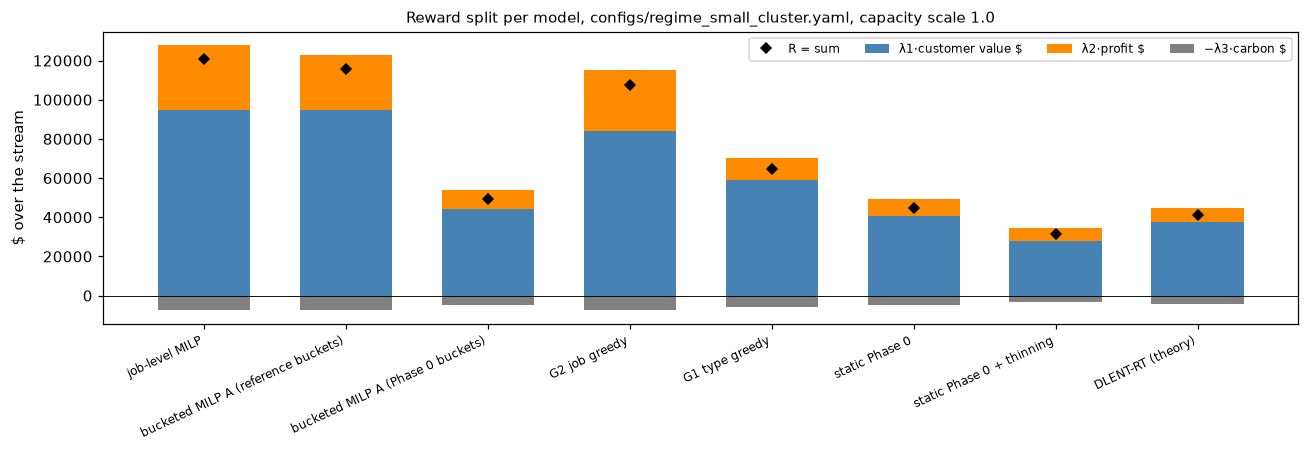

In [30]:
SPLIT0 = reward_split(B0, SETS0)
display(SPLIT0.style.format(precision=2))
plot_split(SPLIT0, f"Reward split per model, {REGIME or 'committed config'}, capacity scale 1.0", "fig10_reward_split")

## Section 10b: Oversize jobs (A_ij > c_i on some resource; capacity scale 1.0)

Without `drop_jobs_exceeding_capacity`, jobs larger than c stay in H and the stream: the physical gate rejects every
one of them that a policy wants, and Phase 0's fluid LP still counts their volume. Counts, their share of Phase 0's
profitable load Σ_{r̃ > 0} p_j·v_ij (a job's A is its type's snapped profile, so the share is exact), ρ = profitable
load / c with and without them, and the physical rejects per model (with how many of them are oversize jobs).

In [31]:
S_o, c_o, ds_o, st_o = B0.S, B0.c, R0["ds"], R0["st0"]
over_S = np.any(S_o.A > c_o[None, :], axis=1)
over_H = np.any(ds_o.H.A > c_o[None, :], axis=1)
k_o = st_o.grid.assign(st_o.bids.v_rate, st_o.myerson)
tid_o = assign_type_ids(st_o.type_space, np.asarray(k_o), ds_o.H.priority, ds_o.H.hw_idx)
_, _, A_to = type_arrays(st_o.type_space, st_o.grid)
jj_o = np.maximum(tid_o, 0)
prof_o = (tid_o >= 0) & (st_o.r_tilde[jj_o] > 0)
vol_o = A_to[jj_o] * ds_o.H.duration_steps[:, None] / ds_o.H_span_steps
load_o = vol_o[prof_o].sum(axis=0)
assert np.allclose(load_o, (st_o.p * (st_o.r_tilde > 0)) @ st_o.v, rtol=1e-9)    # = the LP's profitable load
OVER = pd.Series({
    "c (norm) CPU, RAM": str(np.round(c_o, 6).tolist()),
    "oversize stream jobs": f"{int(over_S.sum()):,} ({100 * over_S.mean():.2f}%)",
    "oversize H jobs": f"{int(over_H.sum()):,} ({100 * over_H.mean():.2f}%)",
    "share of P0 profitable load from oversize, CPU %": 100 * vol_o[prof_o & over_H, 0].sum() / load_o[0],
    "share of P0 profitable load from oversize, RAM %": 100 * vol_o[prof_o & over_H, 1].sum() / load_o[1],
    "rho = P0 profitable load / c, CPU": load_o[0] / c_o[0], "rho, RAM": load_o[1] / c_o[1],
    "rho without oversize, CPU": vol_o[prof_o & ~over_H, 0].sum() / c_o[0],
    "rho without oversize, RAM": vol_o[prof_o & ~over_H, 1].sum() / c_o[1],
    "stream Σ R_job⁺ of oversize jobs $": float(np.maximum(B0.R, 0)[over_S].sum()),
}, name="value")
display(OVER.to_frame())
prow = []
for name, d in ALGS0.items():
    if name.startswith("offline"):
        continue
    adm, phys = d["admit"], d["phys"]
    assert not np.any(adm & over_S)                      # nothing larger than c is ever admitted
    prow.append({"model": name, "admitted": int(adm.sum()), "physical rejects": int(phys.sum()),
                 "physical rejects % of arrivals": 100 * phys.mean(),
                 "of which oversize jobs": int((phys & over_S).sum()),
                 "oversize share of its physical rejects %": 100 * (phys & over_S).sum() / max(int(phys.sum()), 1)})
OVER_PHYS = pd.DataFrame(prow).set_index("model")
display(OVER_PHYS.style.format(precision=2))

,value
"c (norm) CPU, RAM","[0.401424, 0.261621]"
oversize stream jobs,"1,680 (10.97%)"
oversize H jobs,"2,158 (21.58%)"
"share of P0 profitable load from oversize, CPU %",43.861853
"share of P0 profitable load from oversize, RAM %",37.378803
"rho = P0 profitable load / c, CPU",1.23244
"rho, RAM",1.289217
"rho without oversize, CPU",0.691869
"rho without oversize, RAM",0.807323
stream Σ R_job⁺ of oversize jobs $,14452.733446


,admitted,physical rejects,physical rejects % of arrivals,of which oversize jobs,oversize share of its physical rejects %
model,,,,,
DLENT-RT (online),6657,537,3.51,99,18.44
"static tau* (full stream, ORACLE)",10478,1427,9.32,150,10.51
static Phase 0 (H),9237,670,4.38,60,8.96
static Phase 0 (H) + thinning at cap,6253,327,2.14,42,12.84
"G1 (type greedy, cumulative r~)",10377,1290,8.43,167,12.95
"G2 (job greedy, R_job > 0)",10616,2224,14.53,383,17.22


## Section 11: Part 2 — the same ladder at f = 0.2 with `drop_jobs_exceeding_capacity`

**A different configuration from Sections 1–10:** `BASE` with capacity `fraction_of_concurrency_quantile`,
q = 0.7, fraction 0.2, and `capacity.drop_jobs_exceeding_capacity = true` (jobs with A_ij > c_i leave H and the stream).
Fresh Phase 0, DLENT-RT run, benchmarks and policies on that configuration (same seed); then the same ladder,
decomposition and reward split as Sections 9–10.

f = 0.2: c = [0.53523 0.34883]  dropped {'n_H': 1423, 'n_stream': 977}  |H| = 8,577  |stream| = 14,331  s_C = 533.4979  tau_0 = [0. 0.]
DLENT-RT: phases 6 {'test1': 0, 'test2': 0, 'test3': 0, 'timeout': 5, 'horizon': 1}  R = 38,222.30  (243 s)


,realised $,% of job-level MILP,% of feasible ceiling,gap to row above $
row,,,,
"job-level, no capacity (Σ R_job⁺)","123,757.69",110.20,100.00,nan
feasible ceiling (Σ R_job⁺ over A ≤ c),"123,757.69",110.20,100.00,-0.00
job-level MILP,"112,304.68",100.00,90.75,"11,453.01"
bucketed MILP A (reference buckets),"108,479.99",96.59,87.66,"3,824.69"
bucketed MILP A (Phase 0 buckets),"46,528.00",41.43,37.60,"61,951.99"
fluid OPT,"119,169.15",106.11,96.29,"-72,641.15"
fluid OPT on feasible types only,"119,169.15",106.11,96.29,-0.00
G2 job greedy,"102,752.91",91.49,83.03,"16,416.24"
G1 type greedy,"65,408.71",58.24,52.85,"37,344.21"


fluid OPT on feasible types only: {'fluid feasible-types tau': [0.0, 0.0], 'fluid feasible-types tau is 0': True, 'fluid (all types) tau': [0.0, 0.0], 'types removed (A > c), populated': 0, 'types populated': 2758, 'stream jobs that fit': 14331, 'stream jobs': 14331}


,$,% of job MILP,change $,attributed to
step,,,,
static Phase 0,44733.34,39.83,nan,nan
static Phase 0 + thinning,31032.86,27.63,-13700.48,cost of thinning (same frozen oracle)
DLENT-RT (theory),38222.30,34.03,7189.44,"learning / estimation (ReInit, tests, phase-wise thinning)"


,status,gap,runtime s,candidates,unseen jobs,unseen types,chosen with R_job<0,peak true occ / c
MILP,,,,,,,,
job-level,Optimization terminated successfully. (HiGHS S...,0.000049,1.834836,NaN,NaN,NaN,NaN,NaN
bucketed A (reference),Optimization terminated successfully. (HiGHS S...,0.000094,2.139996,11551.0,0.0,0.0,509.0,"[0.9997, 0.9992]"
bucketed A (phase0),Optimization terminated successfully. (HiGHS S...,0.000015,0.129663,9561.0,2621.0,1042.0,697.0,"[0.9989, 0.9995]"


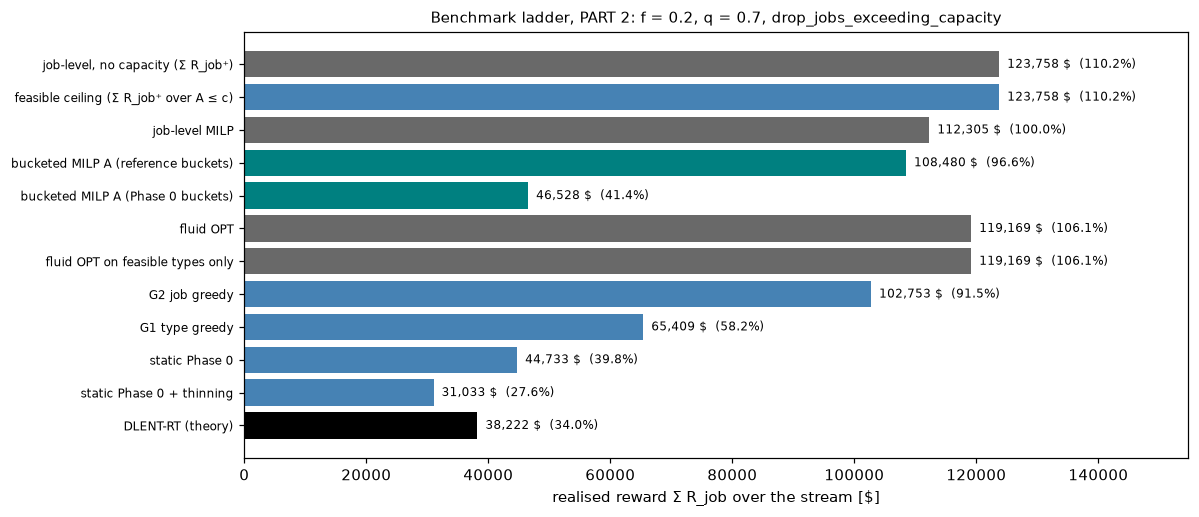

,λ1·customer value $,λ2·profit $,−λ3·carbon $,R $,admitted
row,,,,,
job-level MILP,97536.32,32531.69,-17763.33,112304.68,10962
bucketed MILP A (reference buckets),97508.19,28815.85,-17844.04,108479.99,10798
bucketed MILP A (Phase 0 buckets),44529.94,11069.55,-9071.50,46528.00,9295
G2 job greedy,90321.61,30463.57,-18032.27,102752.91,10765
G1 type greedy,64145.60,13423.52,-12160.41,65408.71,10468
static Phase 0,43147.84,10662.82,-9077.32,44733.34,9304
static Phase 0 + thinning,30311.74,7395.50,-6674.39,31032.86,6250
DLENT-RT (theory),37432.84,8346.63,-7557.17,38222.30,6507


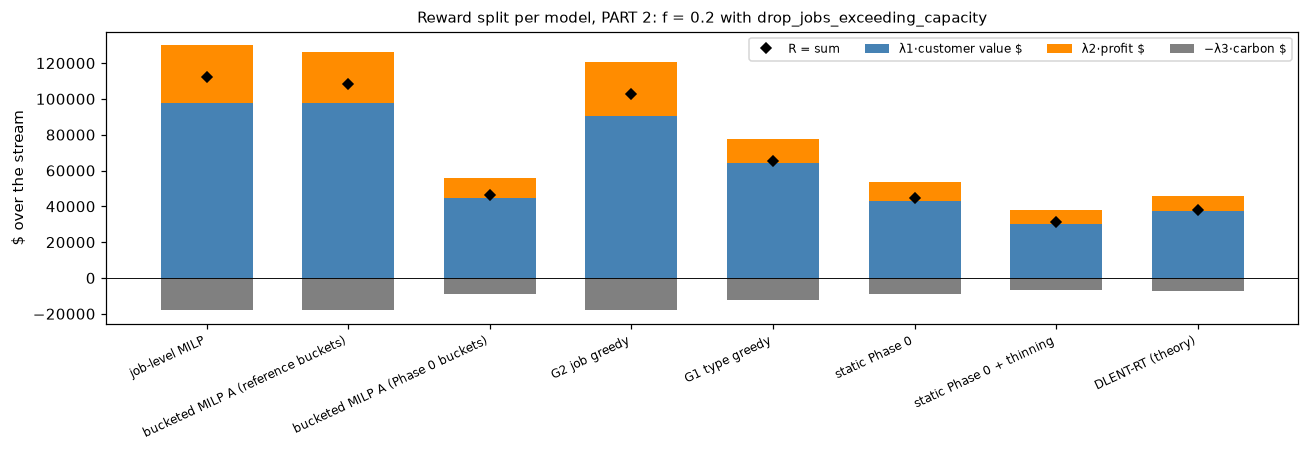

In [32]:
BASE_F02 = apply_overrides(BASE, {"capacity.mode": "fraction_of_concurrency_quantile",
                                  "capacity.concurrency_quantile": 0.7, "capacity.fraction": 0.2,
                                  "capacity.drop_jobs_exceeding_capacity": True}).validate()
t_f = time.time()
DS_F = load_dataset(BASE_F02)
ST_F = run_phase0(DS_F, BASE_F02)
M_F = TheoryModel(DS_F, ST_F, BASE_F02)
RES_F = M_F.run()
B_F = Benchmarks.from_model(M_F)
S_F, R_F = B_F.S, B_F.R
OPT_F = B_F.job_level_opt(time_limit=MILP_TL)
p_cap_f = (1 - M_F.ep.xi) / (1 + M_F.ep.eps_D)
adm_f = np.zeros(S_F.n, bool)
adm_f[[a["i"] for a in RES_F.arrivals if a["admit"]]] = True
assert np.isclose(B_F.score(adm_f), RES_F.summary["R_total"], rtol=1e-10)
ADMITS_F = {"G2 job greedy": run_policy(S_F, M_F.c, JobGreedyPolicy(R_F)).admit,
            "G1 type greedy": run_policy(S_F, M_F.c, TypeGreedyPolicy.from_state(ST_F, S_F, R_F, DS_F.H_span_steps)).admit,
            "static Phase 0": run_static(S_F, M_F.c, ST_F, thin_p=None, u_rand=M_F.u_rand).admit,
            "static Phase 0 + thinning": run_static(S_F, M_F.c, ST_F, thin_p=p_cap_f, u_rand=M_F.u_rand).admit,
            "DLENT-RT (theory)": adm_f}
LAD_F, DEC_F, MILP_F, SETS_F, INFO_F = ladder_tables(B_F, OPT_F, ADMITS_F)
sm_f = RES_F.summary
print(f"f = 0.2: c = {np.round(DS_F.capacity, 5)}  dropped {DS_F.capacity_drop}  |H| = {DS_F.H.n:,}  "
      f"|stream| = {S_F.n:,}  s_C = {ST_F.carbon_price:.4f}  tau_0 = {ST_F.tau}")
print(f"DLENT-RT: phases {sm_f['n_phases']} {sm_f['phase_end_reasons']}  R = {sm_f['R_total']:,.2f}  "
      f"({time.time() - t_f:.0f} s)")
display(LAD_F.style.format({"realised $": "{:,.2f}", "% of job-level MILP": "{:.2f}", "% of feasible ceiling": "{:.2f}", "gap to row above $": "{:,.2f}"}))
print("fluid OPT on feasible types only:", INFO_F)
STD_F = static_thin_dlent(LAD_F)
display(STD_F.style.format(precision=2))
display(DEC_F.style.format(precision=2))
display(MILP_F)
plot_ladder(LAD_F, "Benchmark ladder, PART 2: f = 0.2, q = 0.7, drop_jobs_exceeding_capacity", "fig11_ladder_f02")
SPLIT_F = reward_split(B_F, SETS_F)
display(SPLIT_F.style.format(precision=2))
plot_split(SPLIT_F, "Reward split per model, PART 2: f = 0.2 with drop_jobs_exceeding_capacity", "fig11b_reward_split_f02")

## Check against the reference numbers, figures and `nb03_numbers.md`

Reference values of the run's config (default: week-30 reports; small cluster: `small_cluster_nofilter.md`, f = 0.15),
compared to the cent with this run; every PNG of the notebook is copied to `reports/week30/figs/` (a named regime:
`reports/week30/figs_<regime>/`); every table is written to `nb03_numbers.md` in the run's report folder.

In [33]:
EXPECTED_BY_REGIME = {
    None: {"job-level MILP": 155_397.61, "fluid OPT": 149_478.42, "G2 job greedy": 155_011.00,
           "G1 type greedy": 82_626.18, "static Phase 0": 54_216.40, "DLENT-RT (theory)": 48_391.61,
           "static Phase 0 + thinning": 35_473.28},
    # reports/week30/small_cluster_nofilter.md, f = 0.15 (the cluster frozen in configs/regime_small_cluster.yaml)
    "configs/regime_small_cluster.yaml": {"job-level MILP": 120_742.02, "DLENT-RT (theory)": 40_892.14,
                                          "G2 job greedy": 107_551.45, "G1 type greedy": 64_503.43,
                                          "static Phase 0": 44_716.94, "fluid OPT": 146_395.19,
                                          "feasible ceiling (Σ R_job⁺ over A ≤ c)": 141_126.62}}
EXPECTED = EXPECTED_BY_REGIME[REGIME]
CHECK = pd.DataFrame([{"row": k, "expected $": v, "this run $": LAD0.loc[k, "realised $"],
                       "this run (cents)": round(LAD0.loc[k, "realised $"], 2)} for k, v in EXPECTED.items()]).set_index("row")
CHECK["matches to the cent"] = CHECK["this run (cents)"] == CHECK["expected $"]
display(CHECK)

for f in FIG_DIR.glob("*.png"):
    shutil.copy2(f, FIGS_DIR / f.name)
print(f"figures -> {FIGS_DIR} ({len(list(FIGS_DIR.glob('*.png')))} PNG)")

def _md_csv(name):
    return md_table(pd.read_csv(TAB_DIR / f"{name}.csv", index_col=0), "")

md = [f"# nb03 numbers{' — regime ' + REGIME if REGIME else ''} (generated by the notebook; do not edit by hand)\n",
      f"Commit `{GIT_COMMIT}`, configs/default.yaml blob `{YAML_BLOB}` (the COMMITTED config"
      + (f" + the capacity block of `{REGIME}`, blob `{REGIME_BLOB}`" if REGIME else "")
      + f", via a temporary file); working-copy default.yaml edited: {YAML_WORKING_COPY_EDITED} (not used). "
      f"Seed {BASE.run.seed}, σ = {BASE.bid.sigma}, n0 = {BASE.data.n0:,}. Generated {time.strftime('%Y-%m-%d %H:%M')}.\n",
      "## Check against the reference numbers\n", md_table(CHECK, "row"), "",
      "## Section 9: benchmark ladder (scale 1.0)\n", md_table(LAD0, "row"), "",
      f"fluid OPT on feasible types only: {INFO0}\n",
      "### static → static + thinning → DLENT-RT\n", md_table(STD0, "step"), "",
      "### Decomposition\n", md_table(DEC0, "buckets / bucketed value"), "",
      "### MILPs\n", md_table(MILP0, "MILP"), "",
      "## Section 10: reward split per model (scale 1.0)\n", md_table(SPLIT0, "row"), "",
      "## Section 10b: oversize jobs\n", md_table(OVER.to_frame(), "quantity"), "", md_table(OVER_PHYS, "model"), "",
      "## Section 11: PART 2, f = 0.2, q = 0.7, drop_jobs_exceeding_capacity\n",
      f"c = {np.round(DS_F.capacity, 5).tolist()}, dropped {DS_F.capacity_drop}, |H| = {DS_F.H.n:,}, "
      f"|stream| = {S_F.n:,}, s_C = {ST_F.carbon_price:.4f}, τ₀ = {ST_F.tau.tolist()}, DLENT-RT phases "
      f"{sm_f['n_phases']} {sm_f['phase_end_reasons']}.\n",
      md_table(LAD_F, "row"), "", f"fluid OPT on feasible types only: {INFO_F}\n",
      "### static → static + thinning → DLENT-RT\n", md_table(STD_F, "step"), "",
      "### Decomposition\n", md_table(DEC_F, "buckets / bucketed value"), "",
      "### MILPs\n", md_table(MILP_F, "MILP"), "", "### Reward split\n", md_table(SPLIT_F, "row"), "",
      "## Section 8: capacity × type-grid sweep (summary)\n", md_table(SW_SUM.T, "quantity"), ""]
for name in saved_tabs:
    md += [f"## {name}\n", _md_csv(name), ""]
(REPORT_DIR / "nb03_numbers.md").write_text("\n".join(md))
print("markdown ->", REPORT_DIR / "nb03_numbers.md")

,expected $,this run $,this run (cents),matches to the cent
row,,,,
job-level MILP,120742.02,120742.015802,120742.02,True
DLENT-RT (theory),40892.14,40892.138810,40892.14,True
G2 job greedy,107551.45,107551.453470,107551.45,True
G1 type greedy,64503.43,64503.434552,64503.43,True
static Phase 0,44716.94,44716.937728,44716.94,True
fluid OPT,146395.19,146395.191740,146395.19,True
feasible ceiling (Σ R_job⁺ over A ≤ c),141126.62,141126.615050,141126.62,True


figures -> /Users/francescodangolo/Projects/dlent_rt/reports/week30/figs_small_cluster (21 PNG)
markdown -> /Users/francescodangolo/Projects/dlent_rt/reports/week30/small_cluster_nb/nb03_numbers.md
